# Divar Real-Estate Ads: Preprocessing

In [2]:
#%pip install -q jdatetime pyproj

In [3]:
import pandas as pd
import numpy as np
import jdatetime
from pyproj import Transformer
import matplotlib.pyplot as plt

In [4]:
pd.__version__

'3.0.5'

## Load Data

<div dir="rtl">

- ستون اول فایل CSV همان index ذخیره‌شده‌ی ردیف‌هاست، پس به‌عنوان index خوانده می‌شود.
- با `low_memory=False` نوع هر ستون از روی کل فایل تشخیص داده می‌شود، نه تکه‌تکه؛ وگرنه بعضی ستون‌ها نوع مخلوط می‌گیرند.

</div>

In [5]:
df = pd.read_csv('../data/Divar.csv', index_col=0, low_memory=False)
df.shape

(1000000, 60)

In [6]:
df.index.is_unique

True

## Step 1: Drop Useless Columns

<div dir="rtl">

- ستون `rent_to_single`: از یک میلیون ردیف فقط ۱۹ مقدار دارد.
- ستون‌های `transformable_credit` و `transformable_rent`: کپی `credit_value` و `rent_value` هستند (هر جا هر دو مقدار دارند، یکسان‌اند).
- ستون `location_radius`: به pin نقشه ربطی ندارد. برای حدود ۹۸,۰۰۰ آگهی بدون مختصات پر است و برای حدود ۴۱۴,۰۰۰ آگهی مختصات‌دار خالی.

</div>

In [7]:
df['rent_to_single'].value_counts(dropna=False)

rent_to_single
NaN      999981
True         18
False         1
Name: count, dtype: int64

In [8]:
pairs = [('transformable_credit', 'credit_value'), ('transformable_rent', 'rent_value')]
for copy_col, original_col in pairs:
    both = df[copy_col].notna() & df[original_col].notna()
    same = (df.loc[both, copy_col] == df.loc[both, original_col]).mean()
    print(copy_col, both.sum(), same)

transformable_credit 352084 1.0
transformable_rent 351247 0.99999430600119


In [9]:
pd.crosstab(df['location_latitude'].isna(), df['location_radius'].isna())

location_radius,False,True
location_latitude,,
False,241203,414405
True,98496,245896


In [10]:
cols_to_drop = ['rent_to_single', 'transformable_credit',
                'transformable_rent', 'location_radius']
df = df.drop(columns=cols_to_drop)
df.shape

(1000000, 56)

## Step 2: "unselect" to Missing

<div dir="rtl">

- مقدار `unselect` یعنی کاربر آن فیلد را انتخاب نکرده، پس همان missing است. این مقدار در ۱۰ ستون دیده می‌شود.
- هیچ placeholder متنی دیگری در جدول نیست: نه رشته‌ی خالی یا خط تیره، و نه متن‌هایی مثل `nan` و `None` و `null`.
- مقدار صفر در `floor` یعنی طبقه‌ی همکف و در `extra_person_capacity` یک مقدار واقعی است، پس هیچ‌کدام missing حساب نمی‌شوند.

</div>

In [11]:
unselect_counts = (df == 'unselect').sum()
unselect_counts[unselect_counts > 0]

deed_type                   569
total_floors_count          125
unit_per_floor              246
has_balcony                 223
has_warm_water_provider    1382
has_heating_system         3118
has_cooling_system         5917
has_restroom                628
building_direction         3207
floor_material             1667
dtype: int64

In [12]:
suspicious = ['', ' ', 'nan', 'NaN', 'None', 'null', '-']
df.isin(suspicious).sum().sum()

np.int64(0)

In [13]:
df = df.replace('unselect', np.nan)
(df == 'unselect').sum().sum()

np.int64(0)

## Step 3: Unify has_balcony

<div dir="rtl">

این ستون چهار نوشتار مختلف دارد: `true` و `True` و `false` و `False`. همه به مقدار واقعی True و False تبدیل می‌شوند. بقیه‌ی ستون‌های boolean از قبل مقدار واقعی True و False دارند.

</div>

In [14]:
df['has_balcony'].value_counts(dropna=False)

has_balcony
NaN      493812
true     392096
false     88855
True      20692
False      4545
Name: count, dtype: int64

In [15]:
balcony_map = {'true': True, 'True': True, 'false': False, 'False': False}
df['has_balcony'] = df['has_balcony'].map(balcony_map)
df['has_balcony'].value_counts(dropna=False)

has_balcony
NaN      493812
True     412788
False     93400
Name: count, dtype: int64

## Step 4: Boolean Columns to the `boolean` Type

<div dir="rtl">

- ستون‌های boolean از روی محتوا پیدا می‌شوند (فقط True و False دارند)، نه از روی اسم. مثلاً `has_heating_system` و `has_cooling_system` و `has_restroom` و `has_warm_water_provider` نوع سیستم را نگه می‌دارند، ولی `rent_credit_transform` و `transformable_price` واقعاً boolean هستند.
- وقتی نوع ستون `object` باشد، یک مقدار missing منطق را بی‌صدا خراب می‌کند: `NaN | True` نتیجه‌ی False می‌دهد و عملگر `~` خطا می‌دهد. نوع `boolean` منطق سه‌مقداری دارد (`NA | True = True` و `NA | False = NA`)، و ستون‌های ترکیبی امکانات دقیقاً به همین نیاز دارند.

</div>

In [16]:
bool_cols = []
for col in df.select_dtypes(include='object').columns:
    values = set(df[col].dropna().unique())
    if values <= {True, False}:
        bool_cols.append(col)
bool_cols

C:\Users\IT CITY\AppData\Local\Temp\ipykernel_2016\4245055697.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


['rent_credit_transform',
 'transformable_price',
 'has_business_deed',
 'has_balcony',
 'has_elevator',
 'has_warehouse',
 'has_parking',
 'is_rebuilt',
 'has_water',
 'has_electricity',
 'has_gas',
 'has_security_guard',
 'has_barbecue',
 'has_pool',
 'has_jacuzzi',
 'has_sauna']

In [17]:
df[bool_cols] = df[bool_cols].astype('boolean')
df.dtypes.value_counts()

str        26
boolean    16
float64    14
Name: count, dtype: int64

## Step 5: Drop the Ad Without a Category

<div dir="rtl">

یک آگهی `cat3_slug` ندارد. این آگهی اجاره‌ی یک صندلی در سالن زیبایی است که ملک به حساب نمی‌آید، و رهن و اجاره‌اش هر دو توافقی است (قیمت ندارد). برای هیچ سؤالی کاربرد ندارد، پس حذف می‌شود.

</div>

In [18]:
df.loc[df['cat3_slug'].isna(), ['cat2_slug', 'city_slug', 'title', 'rent_mode', 'credit_mode']]

,cat2_slug,city_slug,title,rent_mode,credit_mode
338801,commercial-rent,isfahan,اجاره صندلی در آکادمی زیبایی ( خمینی شهر),توافقی,توافقی


In [19]:
df = df.dropna(subset=['cat3_slug'])
df.shape

(999999, 56)

## Step 6: Duplicate Ads

<div dir="rtl">

- تطابق کامل همه‌ی ستون‌ها بیش از حد سخت‌گیرانه است: آگهی‌ای که دوباره منتشر شده، جز ماه در همه‌چیز یکسان است.
- نادیده گرفتن متن بیش از حد سهل‌گیرانه است: آگهی‌های مختلف اغلب مقدارهای رایجی مثل متراژ و قیمت را مشترک دارند.
- کلید استفاده‌شده: متن، شهر، متراژ و همه‌ی فیلدهای قیمت (فروش، رهن، اجاره و سه قیمت شبانه).
- از ۲,۴۶۴ گروه تکراری، ۲,۱۶۴ گروه در چند ماه پخش شده‌اند (انتشار دوباره). بقیه همان آگهی‌اند که در یک ماه چند بار منتشر شده، اغلب با محله‌های مختلف.
- قدیمی‌ترین نسخه نگه داشته می‌شود، پس هر ملک یک بار شمرده می‌شود، آن هم در ماهی که وارد بازار شده.
- حذف نمی‌شوند: متن و شهر یکسان با قیمت یا متراژ متفاوت (۸۸۵ مورد، یعنی به‌روزرسانی قیمت هنگام انتشار دوباره) و متن یکسان در شهر دیگر (۱۹۳ مورد).

</div>

In [20]:
df.duplicated().sum()

np.int64(71)

In [21]:
df.drop(columns=['title', 'description']).duplicated().sum()

np.int64(5943)

In [22]:
dup_key = ['title', 'description', 'city_slug', 'building_size',
           'price_value', 'credit_value', 'rent_value',
           'rent_price_on_regular_days', 'rent_price_on_special_days', 'rent_price_at_weekends']
df.duplicated(subset=dup_key).sum()

np.int64(2590)

In [23]:
dup_rows = df[df.duplicated(subset=dup_key, keep=False)]
dup_rows.sort_values(dup_key)[['title', 'city_slug', 'price_value', 'created_at_month']].head(10)

,title,city_slug,price_value,created_at_month
77507,%یخسازی فرهنگیان رشتیان جهاد حمیدیان دانشجو,rasht,2.650000e+09,2024-11-01 00:00:00
805471,%یخسازی فرهنگیان رشتیان جهاد حمیدیان دانشجو,rasht,2.650000e+09,2024-07-01 00:00:00
66210,( مالکم ) فاز۸ بدون واسطه,pardis-city,2.990000e+09,2024-10-01 00:00:00
764874,( مالکم ) فاز۸ بدون واسطه,pardis-city,2.990000e+09,2024-09-01 00:00:00
384974,(حکیم نظامی) ۵۵ متر نقلی / یک خوابه ٪,mashhad,3.600000e+09,2024-10-01 00:00:00
790884,(حکیم نظامی) ۵۵ متر نقلی / یک خوابه ٪,mashhad,3.600000e+09,2024-11-01 00:00:00
709489,(ملک دربستی) نوساز در ۱۵۰۰ متربنا در۹ واحد۱۶۰ ...,tehran,NaN,2024-12-01 00:00:00
920552,(ملک دربستی) نوساز در ۱۵۰۰ متربنا در۹ واحد۱۶۰ ...,tehran,NaN,2024-11-01 00:00:00
464464,** ۷۵۰ متر در ۳ طبقه بر ملک **,arak,NaN,2024-12-01 00:00:00
674640,** ۷۵۰ متر در ۳ طبقه بر ملک **,arak,NaN,2024-10-01 00:00:00


In [24]:
months_per_group = dup_rows.groupby(dup_key, dropna=False)['created_at_month'].nunique()
len(months_per_group), (months_per_group > 1).sum()

(2464, np.int64(2164))

In [25]:
# stable sort + keep='first' keeps the earliest copy of each ad
df = df.sort_values('created_at_month', kind='stable')
df = df.drop_duplicates(subset=dup_key, keep='first')
df = df.sort_index()
df.shape

(997409, 56)

In [26]:
df.duplicated(subset=dup_key).sum()

np.int64(0)

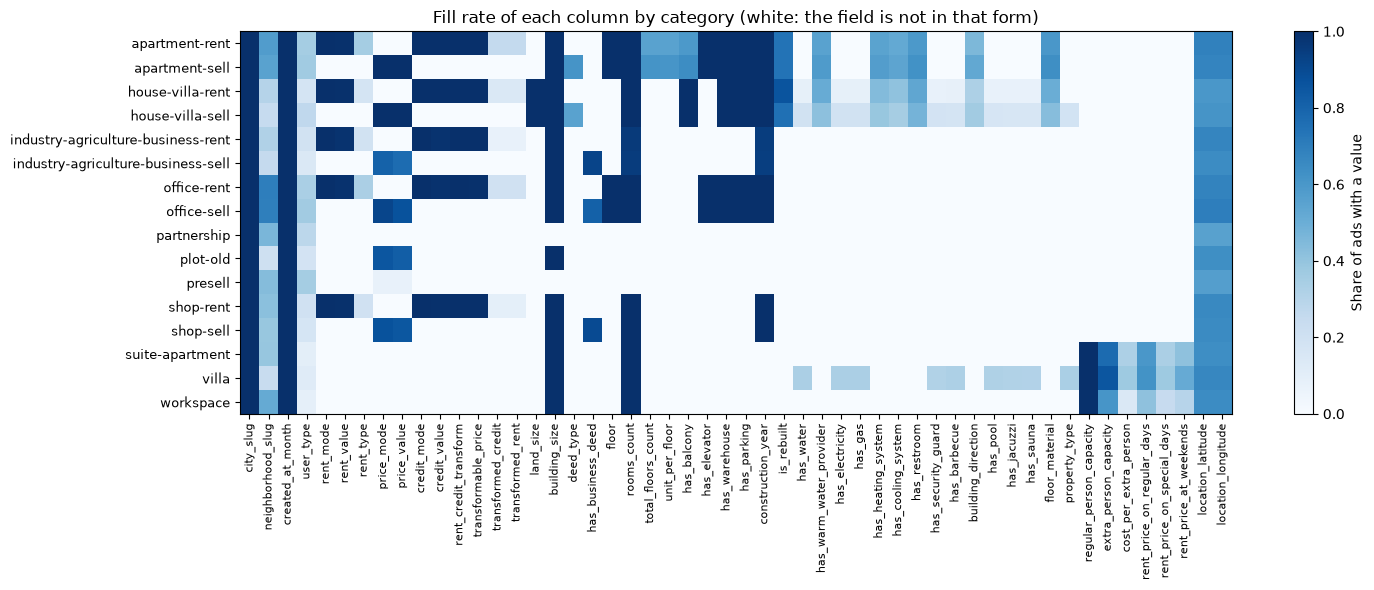

In [27]:
fill_rate = df.drop(columns=['cat2_slug', 'cat3_slug', 'title', 'description']).notna().groupby(df['cat3_slug']).mean()
fig, ax = plt.subplots(figsize=(15, 6))
image = ax.imshow(fill_rate, aspect='auto', cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(fill_rate.shape[1]), fill_rate.columns, rotation=90, fontsize=8)
ax.set_yticks(range(fill_rate.shape[0]), fill_rate.index, fontsize=9)
fig.colorbar(image, ax=ax, label='Share of ads with a value')
ax.set_title('Fill rate of each column by category (white: the field is not in that form)')
plt.tight_layout()
plt.show()

## Step 7: Floor and Capacity Columns to Numbers

<div dir="rtl">

- تنها مقدارهای غیرعددی، بالاترین گزینه‌های فرم هستند: «۳۰ به بالا» برای طبقه، تعداد کل طبقات و نفرات اضافه، و «بیشتر از ۸» برای تعداد واحد در هر طبقه. در داده به شکل <span dir="ltr">`30+`</span> و `more_than_8` نوشته شده‌اند.
- این مقدارها به حد پایینشان تبدیل می‌شوند (۳۰ و ۹). هیچ تحلیلی این چند ردیف را جدا لازم ندارد، پس ستون flag اضافه‌ای ساخته نمی‌شود.
- مقدارهایی مثل `2.0` به ۲ تبدیل می‌شوند، و منفی یک در `floor` یعنی زیرزمین.

</div>

In [28]:
cols = ['floor', 'total_floors_count', 'unit_per_floor', 'extra_person_capacity']
for col in cols:
    values = df[col].dropna()
    print(col, values[pd.to_numeric(values, errors='coerce').isna()].unique())

floor <ArrowStringArray>
['30+']
Length: 1, dtype: str
total_floors_count <ArrowStringArray>
['30+']
Length: 1, dtype: str
unit_per_floor <ArrowStringArray>
['more_than_8']
Length: 1, dtype: str
extra_person_capacity <ArrowStringArray>
['30+']
Length: 1, dtype: str


In [29]:
for col in ['floor', 'total_floors_count', 'extra_person_capacity']:
    df[col] = pd.to_numeric(df[col].replace('30+', '30'))
df['unit_per_floor'] = pd.to_numeric(df['unit_per_floor'].replace('more_than_8', '9'))
df[cols].describe()

,floor,total_floors_count,unit_per_floor,extra_person_capacity
count,540466.000000,303467.000000,301288.000000,23862.000000
mean,2.736198,4.845515,2.270144,4.796077
std,2.407316,2.837589,1.440448,6.001361
min,-1.000000,2.000000,1.000000,0.000000
25%,1.000000,4.000000,1.000000,2.000000
50%,2.000000,4.000000,2.000000,3.000000
75%,4.000000,5.000000,3.000000,5.000000
max,30.000000,30.000000,9.000000,30.000000


## Step 8: Construction Year and Rooms to Numbers

<div dir="rtl">

- سال‌ها با ارقام فارسی نوشته شده‌اند. فرم گزینه‌ی ۱۳۷۰ ندارد، پس «قبل از ۱۳۷۰» خود ۱۳۷۰ و سال‌های قبل را پوشش می‌دهد و به ۱۳۷۰، یعنی حد بالایش، تبدیل می‌شود. چون هیچ آگهی دیگری دقیقاً ۱۳۷۰ ندارد، عدد ۱۳۷۰ به‌تنهایی این گروه را مشخص می‌کند.
- سال ۱۴۰۳، که پرتکرارترین سال است، بررسی شد تا مقدار پیش‌فرض فرم نباشد: اشاره به «نوساز» در متن آگهی‌ها تا ۱۴۰۳ مدام بیشتر می‌شود، و سهم این سال ماه به ماه در طول سال بالا می‌رود، همان‌طور که از ساخت‌وساز واقعی انتظار می‌رود. پس نگه داشته می‌شود.
- تعداد اتاق با کلمه نوشته شده و به صفر تا پنج تبدیل می‌شود. «پنج یا بیشتر» به ۵، یعنی حد پایینش، تبدیل می‌شود.

</div>

In [30]:
df['construction_year'].value_counts().sort_index().head(3)

construction_year
قبل از ۱۳۷۰    20595
۱۳۷۱            5512
۱۳۷۲            1907
Name: count, dtype: int64

In [31]:
persian_digits = str.maketrans('۰۱۲۳۴۵۶۷۸۹', '0123456789')
year_text = df['construction_year'].str.translate(persian_digits)
df['construction_year'] = pd.to_numeric(year_text.replace('قبل از 1370', '1370'))
df['construction_year'].agg(['count', 'min', 'max'])

count    813926.0
min        1370.0
max        1403.0
Name: construction_year, dtype: float64

In [32]:
df['rooms_count'].value_counts(dropna=False)

rooms_count
دو              403038
یک              191652
NaN             153619
سه              138237
بدون اتاق        75728
چهار             21308
پنج یا بیشتر     13827
Name: count, dtype: int64

In [33]:
rooms_map = {'بدون اتاق': 0, 'یک': 1, 'دو': 2, 'سه': 3, 'چهار': 4, 'پنج یا بیشتر': 5}
df['rooms_count'] = df['rooms_count'].map(rooms_map)
df['rooms_count'].value_counts(dropna=False).sort_index()

rooms_count
0.0     75728
1.0    191652
2.0    403038
3.0    138237
4.0     21308
5.0     13827
NaN    153619
Name: count, dtype: int64

## Step 9: Dates, Jalali Month Labels and the Main Window

<div dir="rtl">

- ستون `created_at_month` روز اول یک ماه میلادی است و روز دقیق هر آگهی معلوم نیست.
- برچسب شمسی: ماه شمسی‌ای که روز پانزدهم ماه میلادی در آن قرار دارد. این همیشه ماه شمسی‌ای است که بیشترین بخش ماه میلادی را پوشش می‌دهد، ولی فقط ۶۱ تا ۷۳ درصد روزهایش را، پس برچسب‌ها تقریبی‌اند.
- بازه‌ی اصلی: مه تا دسامبر ۲۰۲۴، با ۱۰۸,۰۰۰ تا ۱۳۳,۰۰۰ آگهی در هر ماه. ماه‌های قبل‌تر (حداکثر ۷,۱۸۷ آگهی) به احتمال زیاد آگهی‌هایی‌اند که هنگام شروع جمع‌آوری هنوز فعال بوده‌اند، یعنی یک نمونه‌ی biased. ماه‌های ۲۰۲۵ هم ناقص‌اند. ستون `in_main_window` این بازه را برای سؤال‌های روند ماهانه مشخص می‌کند و هیچ ردیفی حذف نمی‌شود.

</div>

In [34]:
df['created_at_month'] = pd.to_datetime(df['created_at_month'])
df['created_at_month'].dtype

dtype('<M8[us]')

In [35]:
df['created_at_month'].value_counts().sort_index()

created_at_month
2020-02-01         1
2020-12-01         1
2021-02-01         1
2021-05-01         1
2021-06-01         1
2021-11-01         1
2021-12-01         1
2022-01-01         1
2022-02-01         2
2022-03-01         1
2022-04-01         5
2022-05-01         7
2022-06-01         4
2022-07-01         4
2022-08-01         9
2022-09-01         6
2022-10-01         6
2022-11-01         9
2022-12-01        11
2023-01-01        17
2023-02-01        17
2023-03-01        25
2023-04-01        23
2023-05-01        53
2023-06-01        66
2023-07-01        96
2023-08-01       117
2023-09-01       177
2023-10-01       213
2023-11-01       353
2023-12-01       532
2024-01-01       942
2024-02-01      1211
2024-03-01      1881
2024-04-01      7187
2024-05-01    108735
2024-06-01    125524
2024-07-01    133126
2024-08-01    132340
2024-09-01    121234
2024-10-01    125919
2024-11-01    120752
2024-12-01    115595
2025-01-01      1053
2025-02-01       144
2025-03-01         5
Name: count, dtyp

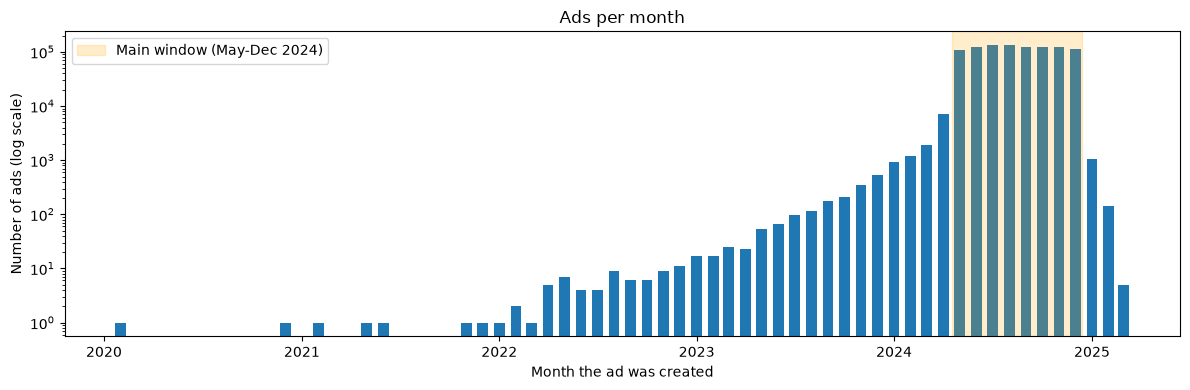

In [36]:
monthly = df['created_at_month'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(monthly.index, monthly.values, width=20)
# bars are centred on the 1st and 20 days wide; the span covers the May-Dec bars
ax.axvspan(pd.Timestamp('2024-04-18'), pd.Timestamp('2024-12-14'), color='orange', alpha=0.2,
           label='Main window (May-Dec 2024)')
ax.set_yscale('log')
ax.set_xlabel('Month the ad was created')
ax.set_ylabel('Number of ads (log scale)')
ax.set_title('Ads per month')
ax.legend()
plt.tight_layout()
plt.show()

In [37]:
df['in_main_window'] = df['created_at_month'].between('2024-05-01', '2024-12-01')
df['in_main_window'].value_counts()

in_main_window
True     983225
False     14184
Name: count, dtype: int64

In [38]:
unique_months = pd.Series(df['created_at_month'].unique())
# each month gets the Jalali month that contains its 15th day
mid_dates = (unique_months + pd.Timedelta(days=14)).dt.date
labels = mid_dates.map(lambda d: jdatetime.date.fromgregorian(date=d).strftime('%Y-%m %B'))
df['jalali_month'] = df['created_at_month'].map(dict(zip(unique_months, labels)))

In [39]:
df.loc[df['in_main_window'], ['created_at_month', 'jalali_month']].value_counts().sort_index()

created_at_month  jalali_month       
2024-05-01        1403-02 Ordibehesht    108735
2024-06-01        1403-03 Khordad        125524
2024-07-01        1403-04 Tir            133126
2024-08-01        1403-05 Mordad         132340
2024-09-01        1403-06 Shahrivar      121234
2024-10-01        1403-07 Mehr           125919
2024-11-01        1403-08 Aban           120752
2024-12-01        1403-09 Azar           115595
Name: count, dtype: int64

## Step 10: Deal Type and Residential Units

<div dir="rtl">

- ستون `deal_type` از `cat2_slug` ساخته می‌شود و چهار مقدار دارد:
  - مقدار `sale`: فروش
  - مقدار `rent`: رهن و اجاره‌ی ماهانه
  - مقدار `daily_rent`: اجاره‌ی شبانه (قیمت برای هر شب)
  - مقدار `service`: پیش‌فروش و مشارکت در ساخت، که ملک آماده نیستند
- هر گروه فیلد قیمت متفاوتی را پر می‌کند، پس قیمت‌هایشان هیچ‌وقت مستقیم با هم مقایسه نمی‌شوند.
- ستون `is_residential_unit` آپارتمان‌ها و خانه‌ها و ویلاها را، چه فروشی و چه اجاره‌ای، مشخص می‌کند: همان خانه‌هایی که فرضیه‌ی متراژ درباره‌ی آن‌هاست.
  - دسته‌ی `plot-old` کنار گذاشته می‌شود: این آگهی‌ها زمین‌اند. تعداد اتاق، سال ساخت و متراژ زمین ندارند، پس `building_size` در آن‌ها همان مساحت زمین است.
  - اجاره‌های شبانه کنار گذاشته می‌شوند: بیشترشان خانه‌ی تفریحی‌اند و مقایسه‌ی بین شهرها را خراب می‌کنند.

</div>

In [40]:
has_value = pd.DataFrame({
    'price': df['price_mode'].notna(),
    'deposit': df['credit_mode'].notna(),
    'rent': df['rent_mode'].notna(),
    'nightly': df['rent_price_on_regular_days'].notna()})
has_value.groupby(df['cat2_slug']).mean().round(3)

,price,deposit,rent,nightly
cat2_slug,,,,
commercial-rent,0.000,0.998,0.998,0.000
commercial-sell,0.856,0.000,0.000,0.000
real-estate-services,0.063,0.000,0.000,0.000
residential-rent,0.000,1.000,1.000,0.000
residential-sell,0.965,0.000,0.000,0.000
temporary-rent,0.000,0.000,0.000,0.605


In [41]:
deal_map = {'residential-sell': 'sale', 'commercial-sell': 'sale',
            'residential-rent': 'rent', 'commercial-rent': 'rent',
            'temporary-rent': 'daily_rent', 'real-estate-services': 'service'}
df['deal_type'] = df['cat2_slug'].map(deal_map)
df['deal_type'].value_counts(dropna=False)

deal_type
sale          595769
rent          352679
daily_rent     29696
service        19265
Name: count, dtype: int64

In [42]:
plot_old = df['cat3_slug'] == 'plot-old'
df.loc[plot_old, ['land_size', 'construction_year', 'rooms_count']].notna().mean()

land_size            0.000008
construction_year    0.000008
rooms_count          0.000008
dtype: float64

In [43]:
df.loc[plot_old, 'title'].sample(5, random_state=0)

256109               زمین ۱۹۰ متری رشت سنگر
763683         زمین شمالی قسمت سوم یزدانشهر
86757                       زمین باغی فرارت
850776                  ۲۰۰۰ متر زمین صنعتی
299833    زمینی به مساحت ۵ هکتار با آب قنات
Name: title, dtype: str

In [44]:
residential_units = ['apartment-sell', 'apartment-rent', 'house-villa-sell', 'house-villa-rent']
df['is_residential_unit'] = df['cat3_slug'].isin(residential_units)
df['is_residential_unit'].value_counts()

is_residential_unit
True     700051
False    297358
Name: count, dtype: int64

## Step 11: Metropolis Label

<div dir="rtl">

- فایل دسته‌بندی ۲۴۰ شهر دارد: ۹ کلان‌شهر و ۲۳۱ شهر کوچک. هر ۹ کلان‌شهر با همان slug در داده وجود دارند.
- در داده ۱۸۱ شهر (۳۶,۶۴۴ آگهی) هست که در فایل نیستند. این‌ها شهرهای کوچک‌ترند، پس برچسب غیر کلان‌شهر می‌گیرند.
- دو آگهی شهر ندارند. برچسبشان missing می‌ماند، نه غیر کلان‌شهر.
- برچسب از روی `city_slug` ثبت‌شده در آگهی است. آگهی‌هایی که زیر یک شهر بزرگ ثبت شده‌اند ولی جای دیگری هستند، بعداً در بررسی مختصات flag می‌خورند.

</div>

In [46]:
cities = pd.read_csv('../data/iran_city_classification.csv')
cities.columns = ['city_slug', 'city_type']
cities['city_type'].value_counts()

city_type
شهر کوچک    231
کلان‌شهر      9
Name: count, dtype: int64

In [47]:
metro_cities = cities.loc[cities['city_type'].str.startswith('کلان'), 'city_slug']
metro_cities.isin(df['city_slug']).sum()

np.int64(9)

In [48]:
outside_file = ~df['city_slug'].isin(cities['city_slug']) & df['city_slug'].notna()
df.loc[outside_file, 'city_slug'].value_counts()

city_slug
langarud                1454
andimeshk               1361
qorveh                   867
garmsar                  838
bandar-Imam-khomeini     786
                        ... 
goli-dagh                  5
maraveh-tapeh              5
khoour                     3
yanghagh                   2
tatar-olya                 1
Name: count, Length: 181, dtype: int64

In [49]:
df['is_metro'] = df['city_slug'].isin(metro_cities).astype('boolean')
df.loc[df['city_slug'].isna(), 'is_metro'] = pd.NA
df['is_metro'].value_counts(dropna=False)

is_metro
False    533756
True     463651
<NA>          2
Name: count, dtype: Int64

## Step 12: Text Normalization

<div dir="rtl">

همه‌ی ستون‌هایی که در ادامه از متن ساخته می‌شوند با regex کار می‌کنند، و regex کاراکتر به کاراکتر مقایسه می‌کند. فقط مشکل‌هایی که در داده دیده شدند اصلاح می‌شوند:
- ارقام فارسی و عربی به ارقام انگلیسی تبدیل می‌شوند (۷۰ درصد متن‌ها ارقام فارسی دارند)، و «ى» عربی به «ی». حروف «ي» و «ك» عربی در داده وجود ندارند.
- نیم‌فاصله (ZWNJ) به فاصله تبدیل می‌شود (۱۷ درصد متن‌ها)، تا «بدون‌استخر» به «بدون استخر» تبدیل شود و الگوهایی که روی شروع کلمه کار می‌کنند باز هم درست کار کنند.
- کشیده، اعراب و کاراکترهای نامرئی جهت متن حذف می‌شوند (روی هم حدود ۵ درصد متن‌ها).
- هر رشته‌ای از فاصله‌ها (از جمله خط جدید) به یک فاصله تبدیل می‌شود. متنی که در نهایت خالی شود، missing می‌شود.

</div>

In [50]:
text = df['title'].fillna('') + ' ' + df['description'].fillna('')
text.str.contains('پیش ?فروش').sum(), text.str.contains('بالکن').sum()

(np.int64(13644), np.int64(88137))

In [51]:
# Arabic-Indic digits, and Arabic 'ى' to Persian 'ی'
arabic_chars = str.maketrans('\u0660\u0661\u0662\u0663\u0664\u0665\u0666\u0667\u0668\u0669\u0649',
                             '0123456789ی')
# kashida, diacritics, ZWJ and direction marks
drop_chars = '[\u0640\u064b-\u0652\u200d\u200e\u200f]'
for col in ['title', 'description']:
    text = df[col].str.translate(persian_digits).str.translate(arabic_chars)
    text = text.str.replace(drop_chars, '', regex=True)
    text = text.str.replace('\u200c', ' ', regex=False)
    text = text.str.replace(r'\s+', ' ', regex=True).str.strip()
    df[col] = text.replace('', np.nan)

In [52]:
text = df['title'].fillna('') + ' ' + df['description'].fillna('')
text.str.contains('پیش ?فروش').sum(), text.str.contains('بالکن').sum()

(np.int64(14019), np.int64(88300))

In [53]:
leftover = '[\u06f0-\u06f9\u0660-\u0669\u0649\u0640\u064b-\u0652\u200c-\u200f]'
df['title'].str.contains(leftover).sum(), df['description'].str.contains(leftover).sum()

(np.int64(0), np.int64(0))

In [54]:
df[['title', 'description']].isna().sum()

title          53
description     1
dtype: int64

## Step 13: Combined Amenity Columns

<div dir="rtl">

فیلدهای امکانات لوکس فقط در فرم ویلا وجود دارند و بیشترشان خالی‌اند؛ خیلی از آگهی‌ها امکانات را فقط در متن نام می‌برند.
- ستون `has_X_combined` وقتی True است که فرم بگوید True، **یا** متن بدون زمینه‌ی منفی به آن امکان اشاره کند. فقط وقتی False است که فرم بگوید False و متن هم به آن اشاره نکند. در بقیه‌ی حالت‌ها missing است. ستون‌های اصلی فرم دست نمی‌خورند.
- کلمه‌ها: برای بالکن «بالکن» یا «تراس» (تراس هم مثل بالکن در ۹۹ درصد موارد با True فرم هم‌خوانی دارد)، و برای نگهبان «نگهبان» یا «سرایدار» یا «لابی من». کلمه‌های شبیه کنار گذاشته می‌شوند: «سوناتا» (یک خودرو)، «استخراج»، «لابی مناسب» و «تراست».
- زمینه‌های منفی برای همه‌ی امکانات: نفی («بدون»، «فاقد»، «ندارد») و امکان ساخت («قابلیت ساخت»، «جای»). برای استخر و سونا، مکان‌های نزدیک و اسم خیابان هم منفی حساب می‌شوند («جنب استخر»، «خیابان سونا»)؛ برای بقیه‌ی امکانات این عبارت‌ها مثبت‌اند («دسترسی به بالکن»، «کوچه نگهبانی دار»).
- مرز کلمه (word boundary): هیچ حرف فارسی یا عربی نباید درست قبل یا بعد از کلمه باشد. علائم نگارشی حرف نیستند، پس «،» هم کلمه‌ها را جدا می‌کند: در «استخر،سونا،جکوزی» هر سه امکان پیدا می‌شوند (سونا در ۱۰,۰۰۰ آگهی، به‌جای ۹,۱۰۵ آگهی). کل بلوک عربی یونیکد، از U+0600 تا U+06FF، به‌عنوان «حرف» استفاده نمی‌شود، چون «،» و «؛» و «؟» را هم شامل می‌شود.
- استخر: استخرهای ذخیره‌ی آب کنار گذاشته می‌شوند، و در دسته‌های زمین و کشاورزی از متن استفاده نمی‌شود، چون آنجا «استخر» بیشتر مخزن آبیاری است.
- بالکن: برای مغازه و ملک صنعتی یا کشاورزی از متن استفاده نمی‌شود. در این دسته‌ها ۹,۷۰۴ آگهی به بالکن اشاره کرده‌اند، ولی منظورشان نیم‌طبقه است («کف ۵۰ متر، بالکن ۲۵ متر») و فرمشان هم فیلد بالکن ندارد.
- هر جا فرم مقدار دارد، برای بالکن اشاره‌ی متن در ۹۹ درصد موارد با فرم هم‌خوانی دارد، ولی برای امکانات لوکس فقط در ۵۳ تا ۶۳ درصد. عنوان‌هایی مثل «ویلا استخردار» که فرمشان False است نشان می‌دهند False فرم قابل اعتماد نیست، پس متن ملاک است.
- امکانات مشاعات ساختمان (مثلاً استخر ساختمان) هم به معنی داشتن آن امکان حساب می‌شوند.

</div>

In [55]:
text = df['title'].fillna('') + ' ' + df['description'].fillna('')
# Persian/Arabic letters only; punctuation is not a letter, so it counts as a word boundary
letter = r'[\u0621-\u064A\u066E-\u06D3\u06D5\u06FA-\u06FF]'
word_start = f'(?<!{letter})'
word_end = f'(?!{letter})'

def text_mentions(words, near_place=False):
    w = f'(?:{words})'
    mentioned = text.str.contains(word_start + w)
    # negative contexts: negation, then 'can be built' / 'room for'
    negative = text.str.contains(word_start + f'(?:بدون|فاقد) {w}')
    negative |= text.str.contains(word_start + f'{w}{letter}* (?:ندارد|نداره|ندارند|نیست)' + word_end)
    negative |= text.str.contains(word_start + f'(?:(?:امکان|قابلیت|مجوز) (?:ساخت |احداث |اجرای )?|جای |جا برای ){w}')
    # pool and sauna only: nearby places and street names
    if near_place:
        negative |= text.str.contains(word_start + f'(?:نزدیک|نزدیکی|نزدیک به|دسترسی به|فاصله تا|جنب|مجاور|روبروی|خیابان|بلوار|کوچه|میدان|خ) {w}')
    return mentioned & ~negative

In [56]:
sample = pd.Series(['استخر،سونا،جکوزی', 'سوناتا مدل 90'])
sample.str.contains(word_start + 'سونا(?!ت)')

0     True
1    False
dtype: bool

In [57]:
# the whole Arabic Unicode block, punctuation included
block = r'(?<![\u0600-\u06FF])'
text.str.contains(block + 'سونا(?!ت)').sum(), text.str.contains(word_start + 'سونا(?!ت)').sum()

(np.int64(9105), np.int64(10000))

In [58]:
# (?!...) drops look-alike words, e.g. the car model Sonata
text_found = {
    'balcony': text_mentions('بالکن|بالکون|تراس(?!ت)'),
    'pool': text_mentions('استخر(?!اج)', near_place=True),
    'sauna': text_mentions('سونا(?!ت)', near_place=True),
    'jacuzzi': text_mentions('جکوزی|جاکوزی'),
    'barbecue': text_mentions('باربیکیو|باربکیو|باربی کیو|باربیکو'),
    'security_guard': text_mentions('نگهبان|سرایدار|لابی ?من' + word_end),
}

In [59]:
water_storage = text.str.contains('استخر ?(?:آب ?)?(?:ذخیره|کشاورزی|پرورش|ماهی)')
land = df['cat3_slug'].isin(['plot-old', 'industry-agriculture-business-sell',
                             'industry-agriculture-business-rent'])
text_found['pool'] &= ~water_storage & ~land

In [60]:
mezzanine = df['cat3_slug'].isin(['shop-sell', 'shop-rent', 'industry-agriculture-business-sell',
                                  'industry-agriculture-business-rent'])
(text_found['balcony'] & mezzanine).sum(), mezzanine.sum()

(np.int64(9704), np.int64(88655))

In [61]:
df.loc[text_found['balcony'] & mezzanine, 'description'].str.extract(r'(.{0,30}بالکن.{0,15})', expand=False).sample(6, random_state=0)

636803           55 متر مغازه + 35 متر بالکن بر اصلی انصاری
349740     15متر زیر زمین 15متر کف 5متر بالکن آب و برق گ...
31513     ده فردیس ✅30 متر همکف ✅30 متر بالکن ✅شیک و تمی...
732279             60 متر مغازه با نیم بالکن 40 متری نما رو
696927    اده ⬅️ سرویس بهداشتی ⬅️ 23متر بالکن ⬅️ مناسب ب...
21999     ی و نورپردازی شده دارای دو تا بالکن با ابعاد 6...
Name: description, dtype: str

In [62]:
text_found['balcony'] &= ~mezzanine

In [63]:
for name, found in text_found.items():
    labelled = df[f'has_{name}'].notna() & found
    print(name, labelled.sum(), round(df.loc[labelled, f'has_{name}'].mean(), 3))

balcony 106202 0.993
pool 5514 0.54
sauna 332 0.587
jacuzzi 1391 0.631
barbecue 1331 0.63
security_guard 6071 0.533


In [64]:
conflict = (df['has_pool'] == False) & text_found['pool']
df.loc[conflict, 'title'].sample(8, random_state=0)

276482                          استخردار/نمارومی/کلیدنخورده
398024                       ویلا دوبلکس روفدار استخردار272
385117    فروش و تهاتر/500 متر ویلای مدرن/ در شهریار کردزار
970428                                      هفت باغ 2100متر
991857                   بدون واسطه پلاک جنگل سنددار180متری
494368                              ویلادر متل قو عباس اباد
962014                           هر طرف بشینی جنگلو می بینی
695978                               ویلا استخر دار/230متری
Name: title, dtype: str

In [66]:
# boolean dtype: NA | True = True, NA | False = NA
for name, found in text_found.items():
    df[f'has_{name}_combined'] = df[f'has_{name}'] | found

In [67]:
summary = pd.DataFrame({
    'form_true': [(df[f'has_{n}'] == True).sum() for n in text_found],
    'combined_true': [(df[f'has_{n}_combined'] == True).sum() for n in text_found]},
    index=list(text_found))
summary

,form_true,combined_true
balcony,411766,455732
pool,3705,34709
sauna,1391,11180
jacuzzi,2267,16903
barbecue,7787,15493
security_guard,6652,69391


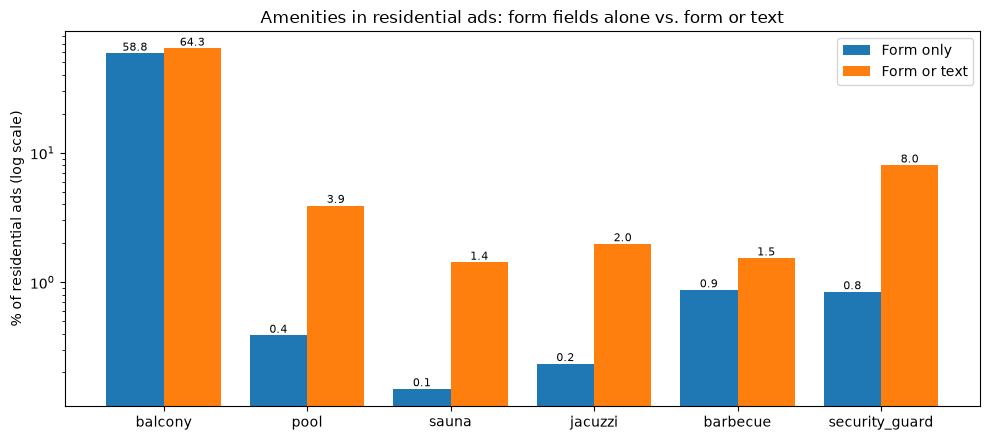

In [68]:
residential = df['is_residential_unit']
names = list(text_found)
form_share = [df.loc[residential, f'has_{n}'].fillna(False).mean() * 100 for n in names]
combined_share = [df.loc[residential, f'has_{n}_combined'].fillna(False).mean() * 100 for n in names]
x = np.arange(len(names))
fig, ax = plt.subplots(figsize=(10, 4.5))
form_bars = ax.bar(x - 0.2, form_share, width=0.4, label='Form only')
combined_bars = ax.bar(x + 0.2, combined_share, width=0.4, label='Form or text')
ax.bar_label(form_bars, fmt='%.1f', fontsize=8)
ax.bar_label(combined_bars, fmt='%.1f', fontsize=8)
ax.set_xticks(x, names)
ax.set_yscale('log')
ax.set_ylabel('% of residential ads (log scale)')
ax.set_title('Amenities in residential ads: form fields alone vs. form or text')
ax.legend()
plt.tight_layout()
plt.show()

## Step 14: Keyword Features, Wanted Ads and Partial Offers

<div dir="rtl">

- ستون‌های keyword، یعنی `mentions_X`، با همان روش ستون‌های امکانات ساخته می‌شوند: شروع کلمه و بدون زمینه‌ی منفی. این کلمه‌ها نگه داشته شدند چون هر کدام در یک مدل خطی اکتشافی، با کنترل متراژ، سن بنا، تعداد اتاق، طبقه، امکانات و موقعیت، قیمت آپارتمان را دست‌کم ۵ درصد تغییر می‌دادند. چند نمونه: مسکن مهر ۳۰ درصد کمتر، اقساطی ۳۲ درصد کمتر، لابی ۱۷ درصد بیشتر، نوساز ۱۱ درصد بیشتر و وام ۸ درصد کمتر. کلمه‌هایی که اثر کمتری داشتند یا یک ستون فرم آن‌ها را پوشش می‌داد (سند تک‌برگ، بازسازی‌شده) حذف شدند. انتخاب نهایی در نوت‌بوک مدل انجام می‌شود.
- ستون `mentions_key_money` (سرقفلی) برای تحلیل‌های تجاری نگه داشته شده، نه برای آپارتمان. در فروش مغازه، آگهی‌هایی که به سرقفلی اشاره می‌کنند کمتر سند تجاری دارند (۳۶ درصد در برابر ۴۸ درصد) و قیمت هر مترشان بالاتر است (در Step 19)، پس یک confounder برای فرضیه‌ی سند تجاری است.
- ستون `mentions_agency` جای `user_type` را می‌گیرد، که ۷۱ درصد missing است و بعد از اکتبر ۲۰۲۴ اصلاً وجود ندارد. هر جا `user_type` معلوم است، اشاره به مشاور املاک در ۹۷ تا ۹۹ درصد موارد یعنی آگهی مشاور (نرخ پایه ۸۹ درصد است).
- ستون `is_wanted_ad` آگهی‌هایی را مشخص می‌کند که یک ملک کامل عرضه نمی‌کنند: آگهی‌های درخواست که اول‌شخص نوشته شده‌اند («خونه میخوام»، «خریدارم»، «دنبال ... هستم») و آگهی‌های هم‌خانه (قیمت سهم یک نفر است). فقط عنوان جست‌وجو می‌شود، و عنوان‌هایی که فعل فروش یا لحن دوم‌شخص دارند («اگر دنبال ... هستید») کنار گذاشته می‌شوند.
- ستون `is_partial_offer` آگهی‌هایی را مشخص می‌کند که قیمتشان فقط برای بخشی از ملک است. اینجا هم فقط عنوان جست‌وجو می‌شود:
  - اجاره: یک صندلی، میز، تخت یا لاین کاری در سالن یا دفتر («اجاره صندلی آرایشگاه»، «اجاره میز ناخن»). قیمت مال یک جای کار است، ولی متراژ مال کل فضاست.
  - فروش آپارتمان یا خانه: امتیاز عضویت در یک طرح مسکن («مسکن ملی»، «فروش امتیاز آپارتمان»). قیمت مبلغی است که تا حالا پرداخت شده، نه ارزش واحد.
  - کلمه‌ها به نوع معامله گره خورده‌اند («اجاره میز»، «فروش امتیاز»)، چون به‌تنهایی معنای دیگری هم دارند: «لاین آسانسور»، «امتیاز آب و برق» (انشعاب) و «روبروی مسکن ملی» (یک نشانی).

</div>

In [69]:
keyword_features = {
    'new_building': 'نوساز|کلید نخورده|تازه ساز',
    'luxury': 'لوکس|لاکچری',
    'shared_facilities': 'مشاعات',
    'lobby': 'لابی',
    'penthouse': 'پنت ?هاوس',
    'teardown': 'کلنگی',
    'loan': 'وام',
    'installments': 'اقساط|قسطی|پیش ?پرداخت',
    'presale': 'پیش ?فروش',
    'mehr_housing': 'مسکن مهر',
    'key_money': 'سرقفلی|سر قفلی',
    'agency': 'املاک|مشاور|بنگاه|کارشناس|کد (?:آگهی|ملک|فایل)',
}
for name, words in keyword_features.items():
    df[f'mentions_{name}'] = text_mentions(words)
df[[f'mentions_{n}' for n in keyword_features]].mean().round(3)

mentions_new_building         0.087
mentions_luxury               0.034
mentions_shared_facilities    0.058
mentions_lobby                0.038
mentions_penthouse            0.001
mentions_teardown             0.014
mentions_loan                 0.058
mentions_installments         0.028
mentions_presale              0.014
mentions_mehr_housing         0.012
mentions_key_money            0.003
mentions_agency               0.383
dtype: float64

In [70]:
pd.crosstab(df['user_type'], df['mentions_agency'], normalize='index').round(3)

mentions_agency,False,True
user_type,,
شخصی,0.872,0.128
مشاور املاک,0.299,0.701


In [71]:
shop_sale = df['cat3_slug'] == 'shop-sell'
pd.crosstab(df.loc[shop_sale, 'mentions_key_money'], df.loc[shop_sale, 'has_business_deed'], normalize='index').round(3)

has_business_deed,False,True
mentions_key_money,,
False,0.523,0.477
True,0.644,0.356


In [72]:
title = df['title'].fillna('')
# first-person wanted phrases and roommate ads
wanted = title.str.contains(word_start + '(?:خریدار(?:م|یم)|خریداری می ?کنم|می ?خرم|اجاره می ?کنم|رهن می ?کنم|می ?خوا(?:هم|م)|میخام|نیاز دارم|نیاز ?مند(?:یم)?|خواستار|جویای|متقاضی|هم ?خونه|هم ?خانه)' + word_end)
# 'looking for ...' titles
wanted |= title.str.contains(r'^دنبال|' + word_start + 'دنبال.{0,40}(?:هستم|هستیم|میگردم|می گردم)')
# drop sale verbs and second-person phrasing
wanted &= ~title.str.contains(word_start + '(?:فروش|میفروشم|بفروشم|هستی|هستین|هستید|میگردی|میگردید)' + word_end)
df['is_wanted_ad'] = wanted
df.groupby('deal_type')['is_wanted_ad'].sum()

deal_type
daily_rent     300
rent          5834
sale           247
service        119
Name: is_wanted_ad, dtype: int64

In [73]:
df.loc[df['is_wanted_ad'], 'title'].sample(10, random_state=0)

278898     دنبال خونه اجاره ای هستم متراژ40 ،50متر
375263    خانه دارم خانم هستم همخانه خانم نیازمندم
538447                             اپارتمان همخونه
825848                              درخواست همخونه
753416                     همخونه برای خونه ویلایی
720168              دنبال خانه دربست اجاره ای هستم
607405                   نیازمند همخونه بدون حاشیه
362638                   آقا هستم هم اتاقی میخواهم
173015                                      همخونه
859848                               هم خانه میخام
Name: title, dtype: str

In [74]:
# rent: a work station (chair, desk, bed, service line) inside a salon or office
item = '(?:صندلی|میز|لاین|تخت)'
work_station = title.str.contains(word_start + '(?:(?:اجاره|کرایه|واگذاری)(?: ی)? ' + item
                                  + '|میز ?ناخن|تخت (?:مژه|تتو|فیشال)|لاین (?:ناخن|مژه|رنگ|زیبایی|کراتین|آرایش)|صندلی (?:آرایشگاه|آرایشگری))')
# sale: a membership right in a housing program
membership_right = title.str.contains(word_start + '(?:مسکن ملی|نهضت ملی|(?:فروش|واگذاری) (?:ی )?امتیاز'
                                      + '|امتیاز (?:مسکن|آپارتمان|واحد|تعاونی|پروژه|زمین|خانه))')
sale_home = (df['deal_type'] == 'sale') & df['is_residential_unit']
df['is_partial_offer'] = (work_station & (df['deal_type'] == 'rent')) | (membership_right & sale_home)
df.groupby('cat3_slug')['is_partial_offer'].sum().loc[lambda s: s > 0]

cat3_slug
apartment-rent                           7
apartment-sell                        1044
house-villa-rent                         1
house-villa-sell                        67
industry-agriculture-business-rent       2
office-rent                           1584
shop-rent                              142
Name: is_partial_offer, dtype: int64

In [75]:
df.loc[df['is_partial_offer'], ['cat3_slug', 'title']].sample(10, random_state=0)

,cat3_slug,title
563166,office-rent,اجاره لاین سالن زیبایی در الهیه 25
948430,apartment-sell,آپارتمان مسکن ملی فاز1کوی نیرو
70428,office-rent,اجاره تخت مژه و صندلی رنگ کار /مرزداران
36563,office-rent,اجاره لاین
873789,office-rent,اجاره صندلی رنگولایت
379420,apartment-sell,مسکن ملی سراج 2
353950,apartment-sell,فروش امتیاز آپارتمان شهرداری
384646,apartment-sell,مسکن ملی شهر نیر مسکن
508680,office-rent,اجاره لاین در سالن زیبایی
61179,office-rent,اجاره صندلی ناخن و تخت


## Step 15: Coordinates

<div dir="rtl">

- خارج از ایران: ۴۷ نقطه بیرون از یک کادر تقریبی دور ایران‌اند (عرض جغرافیایی ۲۵ تا ۴۰ و طول جغرافیایی ۴۴ تا ۶۳.۵)، یعنی در دریا یا امارات. این نقطه‌ها missing می‌شوند و مقدار `location_issue` برایشان `outside_iran` است.
- نقطه‌های مشترک (shared pin): هر چه آگهی‌های بیشتری روی یک نقطه‌ی دقیقاً یکسان باشند، نوع ملکشان مخلوط‌تر است. در نقطه‌هایی با ۵ تا ۹ آگهی، ۷۹ درصد آگهی‌ها و در نقطه‌هایی با ۱۰ آگهی یا بیشتر، ۹۷ درصد آگهی‌ها کنار دست‌کم ۳ دسته‌ی مختلف قرار دارند. این نقطه‌ها مرکز شهر یا دفتر مشاورند، نه محل ملک. نقطه‌هایی با ۵ آگهی یا بیشتر، یا با آگهی‌هایی از بیش از یک شهر، missing می‌شوند و برچسب `shared_pin` می‌گیرند. نقطه‌هایی که فقط بین دو آگهی مشترک‌اند (یک ساختمان) نگه داشته می‌شوند.
- دور از شهر: فقط flag می‌خورد و چیزی تغییر نمی‌کند، چون اغلب مختصات درست است و `city_slug` غلط؛ مثلاً آگهی کاشمر که زیر مشهد ثبت شده. مرکز شهر، median مختصات آن شهر است (هیچ قیمتی در آن استفاده نمی‌شود، و این flag نشانه‌ی کیفیت داده است، نه ورودی مدل). آگهی‌هایی که بیش از ۵۰ کیلومتر فاصله دارند flag می‌خورند؛ ۹۹ درصد آگهی‌های تهران در حدود ۲۵ کیلومتری مرکز آن‌اند. شهرهایی که کمتر از ۳۰ آگهی مختصات‌دار دارند flag نمی‌گیرند.

</div>

In [76]:
lat, lon = 'location_latitude', 'location_longitude'
outside = df[lat].notna() & ~(df[lat].between(25, 40) & df[lon].between(44, 63.5))
df['location_issue'] = pd.NA
df.loc[outside, 'location_issue'] = 'outside_iran'
df.loc[outside, [lat, lon]] = np.nan
outside.sum()

np.int64(47)

In [77]:
by_pin = df.groupby([lat, lon])
pin_ads = by_pin['city_slug'].transform('size')
pin_cities = by_pin['city_slug'].transform('nunique')
pin_categories = by_pin['cat3_slug'].transform('nunique')
pin_size = pd.cut(pin_ads, [0, 1, 2, 4, 9, 1000], labels=['1', '2', '3-4', '5-9', '10+']).rename('ads_at_pin')
(pin_categories >= 3).groupby(pin_size, observed=True).agg(['size', 'mean']).round(2)

,size,mean
ads_at_pin,,
1,629160,0.00
2,6378,0.00
3-4,2146,0.34
5-9,2876,0.79
10+,13074,0.97


In [78]:
shared = (pin_ads >= 5) | (pin_cities >= 2)

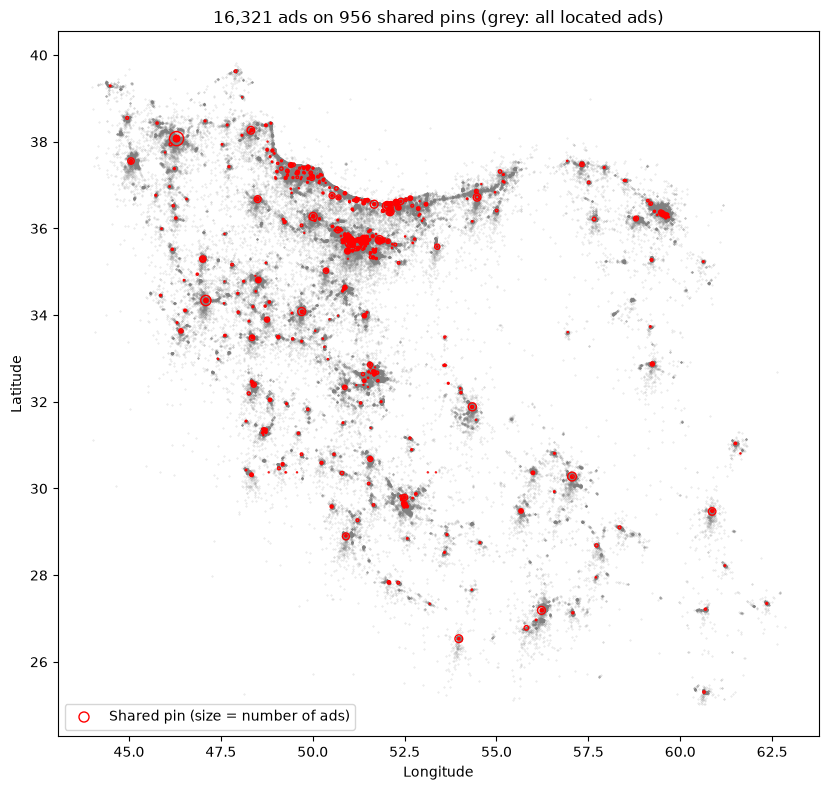

In [79]:
shared_pins = df.loc[shared, [lon, lat]].value_counts()
fig, ax = plt.subplots(figsize=(9, 8))
ax.scatter(df[lon], df[lat], s=0.1, color='grey', alpha=0.3, rasterized=True)
ax.scatter(shared_pins.index.get_level_values(lon), shared_pins.index.get_level_values(lat),
           s=shared_pins.values / 5, facecolors='none', edgecolors='red',
           label='Shared pin (size = number of ads)')
# same km scale on both axes at about 32°N
ax.set_aspect(1 / np.cos(np.radians(32)))
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title(f'{shared.sum():,} ads on {len(shared_pins)} shared pins (grey: all located ads)')
ax.legend(loc='lower left')
plt.tight_layout()
plt.show()

In [80]:
df.loc[shared, 'location_issue'] = 'shared_pin'
df.loc[shared, [lat, lon]] = np.nan
pin_cities.max(), df['location_issue'].value_counts(dropna=False)

(np.float64(36.0),
 location_issue
 <NA>            981041
 shared_pin       16321
 outside_iran        47
 Name: count, dtype: int64)

In [81]:
city_lat = df.groupby('city_slug')[lat].transform('median')
city_lon = df.groupby('city_slug')[lon].transform('median')
city_points = df.groupby('city_slug')[lat].transform('count')
# about 111 km per degree; a degree of longitude shrinks with cos(latitude)
km_north = (df[lat] - city_lat) * 111
km_east = (df[lon] - city_lon) * 111 * np.cos(np.radians(df[lat]))
distance = np.sqrt(km_north**2 + km_east**2)
df['far_from_city'] = (distance > 50).astype('boolean')
df.loc[distance.isna() | (city_points < 30), 'far_from_city'] = pd.NA
distance.quantile([0.5, 0.9, 0.99, 0.999]).round(1), df['far_from_city'].value_counts(dropna=False)

(0.500      4.5
 0.900     14.1
 0.990     62.7
 0.999    283.5
 dtype: float64,
 far_from_city
 False    627842
 <NA>     360532
 True       9035
 Name: count, dtype: Int64)

In [82]:
df.loc[df['far_from_city'] == True, ['city_slug', 'title']].sample(6, random_state=0)

,city_slug,title
381059,tabriz,ویلا باغ در روستای قینر
194745,astara,دربستی
20254,andisheh-new-town,48متر/2 پارکینگه/متمایز در منطقه
244384,fardis-city,142متر خوش نقشه قریشی جنوبی
276560,tabriz,زمین باغ ویلا
532961,mashhad,کاشمر خانه اجاره ای نقلی مرتب


## Step 16: Building and Land Size

<div dir="rtl">

- مقدارهای placeholder (پنج رقم غیرصفر یکسان پشت هم، یا دنباله‌ای مثل 12345) missing می‌شوند.
- حدها از شکل توزیع درمی‌آیند (تعداد آگهی در هر مرتبه‌ی بزرگی): دُم طبیعی توزیع مدام کم می‌شود، پس جایی که تعداد دوباره بالا می‌رود، یا یک جهش دقیقاً روی ۱ متر، نشانه‌ی خطای تایپی است.
  - حداقل ۱۰ متر مربع؛ برای مغازه و فضای کار ۲ متر مربع، چون کیوسک و مغازه‌ی زیرپله واقعی‌اند. مقدار دقیقاً ۱ متر در همه‌ی گروه‌ها یک جهش است.
  - حداکثر ۱۰,۰۰۰ متر برای واحد، مغازه و خانه، و ۱۰۰,۰۰۰ متر برای زمینِ خانه، چون بالای ۱۰۰,۰۰۰ تعداد دوباره بالا می‌رود.
  - زمین و ملک کشاورزی حدی جز حداکثر خود فرم (دقیقاً ۱۰,۰۰۰,۰۰۰) ندارند، چون دُم توزیعشان آرام پایین می‌آید.
- دلیل در `building_size_issue` و `land_size_issue` ثبت می‌شود. مقدارهای داخل حدها، حتی نادرها، به بخش‌های تحلیل سپرده می‌شوند.
- متراژی که در عنوان نوشته شده تست شد و استفاده نشد: بیشتر مغایرت‌ها از عددهای دیگر عنوان می‌آیند (عرض خیابان، بَر ملک، تراس)، و ترمیم فقط مقدارهای خراب ۰.۰۴ درصد آگهی‌ها را درست می‌کرد.

</div>

In [83]:
# 5 identical non-zero digits in a row, or a 12345-style run
placeholder_pattern = '|'.join(str(d) * 5 for d in range(1, 10)) + '|12345|23456|34567|45678|56789|98765'

def is_placeholder(values):
    # missing becomes 0, which never matches
    return values.fillna(0).astype('int64').astype(str).str.contains(placeholder_pattern)

In [84]:
size_group = df['cat3_slug'].map({
    'apartment-sell': 'unit', 'apartment-rent': 'unit', 'office-sell': 'unit', 'office-rent': 'unit',
    'suite-apartment': 'unit', 'shop-sell': 'shop', 'shop-rent': 'shop', 'workspace': 'shop',
    'house-villa-sell': 'house', 'house-villa-rent': 'house', 'villa': 'house',
    'plot-old': 'land', 'industry-agriculture-business-sell': 'land',
    'industry-agriculture-business-rent': 'land'}).rename('size_group')
magnitude_bins = [0, 1, 9, 99, 999, 9999, 99999, 999999, 1e7]
magnitude_labels = ['1', '2-9', '10-99', '100-999', '1k-10k', '10k-100k', '100k-1M', '1M-10M']
magnitude = pd.cut(df['building_size'].mask(is_placeholder(df['building_size'])),
                   magnitude_bins, labels=magnitude_labels)
pd.crosstab(size_group, magnitude)

building_size,1,2-9,10-99,100-999,1k-10k,10k-100k,100k-1M,1M-10M
size_group,,,,,,,,
house,1235,267,60891,130193,4604,388,568,163
land,232,169,7245,109538,29079,5548,1467,596
shop,136,1838,52429,12931,532,91,85,15
unit,291,473,308896,245134,1068,285,361,46


In [85]:
pd.cut(df['land_size'].mask(is_placeholder(df['land_size'])),
       magnitude_bins, labels=magnitude_labels).value_counts(sort=False)

land_size
1              190
2-9             79
10-99        31699
100-999     144537
1k-10k        8018
10k-100k       357
100k-1M        661
1M-10M         130
Name: count, dtype: int64

In [86]:
# per-row limits in m²; land has no upper limit except the form's maximum
min_size = size_group.map({'shop': 2}).fillna(10)
max_size = size_group.map({'land': 1e7}).fillna(10000)
land_min, land_max = 10, 100000

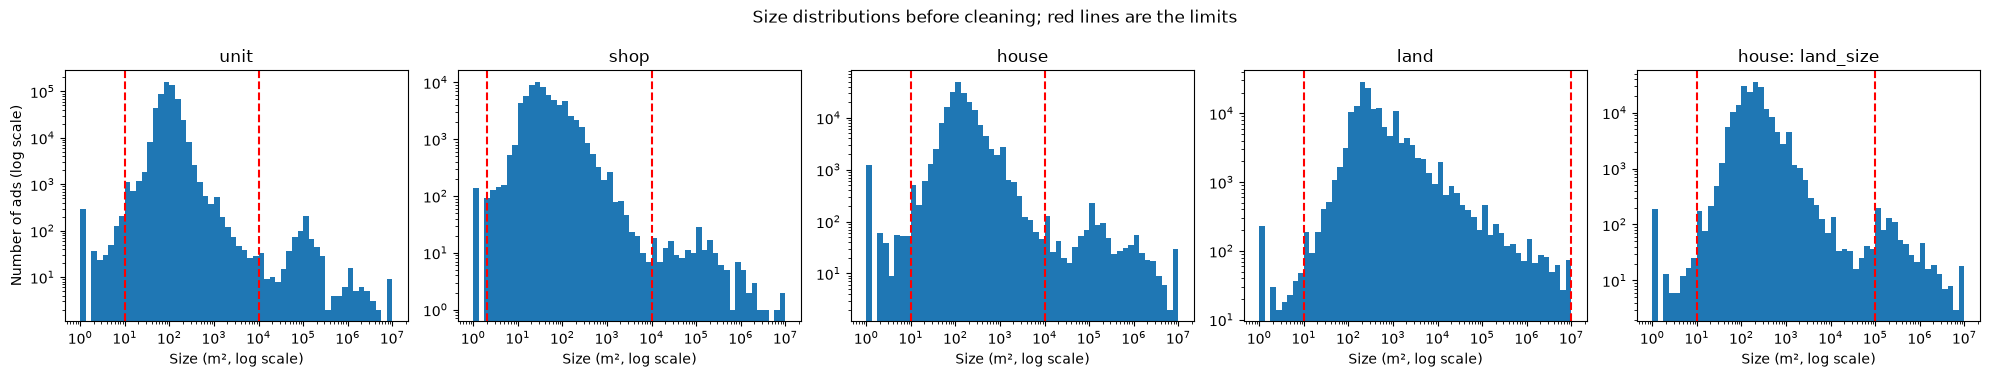

In [87]:
building = df['building_size'].mask(is_placeholder(df['building_size']))
land_area = df['land_size'].mask(is_placeholder(df['land_size']))
panels = [(group, building[size_group == group],
           min_size[size_group == group].iloc[0], max_size[size_group == group].iloc[0])
          for group in ['unit', 'shop', 'house', 'land']]
panels.append(('house: land_size', land_area, land_min, land_max))
bins = np.logspace(0, 7, 57)
fig, axes = plt.subplots(1, 5, figsize=(20, 3.8))
for ax, (name, values, low, high) in zip(axes, panels):
    ax.hist(values.dropna(), bins=bins)
    ax.axvline(low, color='red', linestyle='--')
    ax.axvline(high, color='red', linestyle='--')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_title(name)
    ax.set_xlabel('Size (m², log scale)')
axes[0].set_ylabel('Number of ads (log scale)')
fig.suptitle('Size distributions before cleaning; red lines are the limits')
plt.tight_layout()
plt.show()

In [88]:
for col, low, high in [('building_size', min_size, max_size), ('land_size', land_min, land_max)]:
    placeholder = is_placeholder(df[col])
    implausible = df[col].notna() & ~placeholder & ((df[col] < low) | (df[col] >= high))
    df[f'{col}_issue'] = pd.NA
    df.loc[placeholder, f'{col}_issue'] = 'placeholder'
    df.loc[implausible, f'{col}_issue'] = 'implausible'
    df.loc[placeholder | implausible, col] = np.nan

In [89]:
df['building_size_issue'].value_counts(dropna=False), df['land_size_issue'].value_counts(dropna=False)

(building_size_issue
 <NA>           991402
 implausible      4866
 placeholder      1141
 Name: count, dtype: int64,
 land_size_issue
 <NA>           996046
 implausible      1060
 placeholder       303
 Name: count, dtype: int64)

In [90]:
df.groupby(size_group)['building_size'].agg(['count', 'min', 'median', 'max'])

,count,min,median,max
size_group,,,,
house,195688,10.0,120.0,9985.0
land,153412,10.0,300.0,9700000.0
shop,67730,2.0,35.0,9500.0
unit,555098,10.0,90.0,9888.0


## Step 17: Floor vs Total Floors

<div dir="rtl">

- در ۱,۲۴۹ آگهی طبقه بالاتر از کل طبقات ساختمان است. ۷۲۲ تای آن‌ها دقیقاً یک طبقه بالاترند و یک قطر منظم می‌سازند (طبقه‌ی ۳ از ۲، ۴ از ۳، ۵ از ۴ و ...): این یک قرارداد شماره‌گذاری است (اینکه همکف شمرده شود یا نه)، نه خطا.
- در ۵۲۷ آگهی (۰.۱۷ درصد از ۳۰۳,۴۳۱ آگهی‌ای که هر دو مقدار را دارند) اختلاف دو طبقه یا بیشتر است. نمی‌شود فهمید کدام فیلد غلط است، هیچ سؤال آماری از طبقه استفاده نمی‌کند، و این سهم برای اثر روی مدل خیلی کوچک است، پس داده دست نمی‌خورد.

</div>

In [91]:
floor_gap = df['floor'] - df['total_floors_count']
floor_gap[floor_gap > 0].value_counts().sort_index().head(5)

1.0    722
2.0    244
3.0     85
4.0     46
5.0     23
Name: count, dtype: int64

In [92]:
(floor_gap >= 2).sum(), floor_gap.notna().sum()

(np.int64(527), np.int64(303431))

## Step 18: Prices

<div dir="rtl">

- مقدارهای placeholder در هر هفت فیلد قیمت missing می‌شوند.
- صفر: قیمت فروش یا قیمت شبانه‌ی صفر («مجانی») غیرممکن است و missing می‌شود. رهن صفر، اجاره‌ی ماهانه‌ی صفر (رهن کامل) و هزینه‌ی صفر برای نفر اضافه واقعی‌اند و می‌مانند.
- حدهای قیمت هر متر، مثل متراژ، از تعداد آگهی در هر مرتبه‌ی بزرگی درمی‌آیند: قیمت‌هایی که به هزار یا میلیون تومان تایپ شده‌اند، چند مرتبه پایین‌تر از توده‌ی اصلی یک برآمدگی دوم می‌سازند، و در بالای توزیع تعداد دوباره بالا می‌رود.
  - فروش (تومان برای هر متر): آپارتمان و دفتر از ۱ میلیون تا ۱ میلیارد؛ مغازه از ۱ میلیون تا ۱۰ میلیارد (مغازه‌های بازار)؛ خانه و ویلا از ۱۰۰ هزار تا ۱۰ میلیارد، چون آگهی‌هایشان باغ هم دارد و متراژ، متراژ کل باغ است؛ زمین و ملک کشاورزی از ۱۰ هزار تا ۱ میلیارد.
  - اجاره: رهن به‌علاوه‌ی اجاره با نرخ پروژه (هر ۱ میلیون رهن معادل ۳۰ هزار اجاره‌ی ماهانه)، برای هر متر از ۱۰۰ هزار تا ۱ میلیارد، و برای زمین و ملک کشاورزی از ۱۰۰ تومان تا ۱ میلیارد. اگر خارج از بازه باشد، هم رهن و هم اجاره missing می‌شوند، چون معلوم نیست کدام غلط است.
  - آگهی بدون متراژ: مبلغ کل باید بین ۱ میلیون و ۱۰,۰۰۰ میلیارد تومان باشد.
  - قیمت شبانه از ۱۰۰ هزار تا ۱۰۰ میلیون تومان است. هزینه‌ی نفر اضافه صفر است یا از ۱۰ هزار تا ۱۰ میلیون.
- قیمت‌های خارج از بازه با ضرب در یک ضریب اصلاح نمی‌شوند: ضریب درست مبهم است، و ضریبی که به این دلیل پذیرفته شود که عدد را به بازه‌ی عادی می‌برد، نتیجه را به‌طور ساختگی عادی نشان می‌دهد.
- ستون `price_issue` اولین دلیلِ پیدا شده را نگه می‌دارد. هر نوع معامله فقط فیلدهای قیمت خودش را پر می‌کند، پس یک ستون برای هر آگهی کافی است.
- حدها یک بار در جدول `limits` تعریف می‌شوند. histogramهای پایین نشان می‌دهند هر حد در دره‌ی بین خوشه‌های خطای تایپی و توده‌ی اصلی قرار دارد.

</div>

In [93]:
nightly_cols = ['rent_price_on_regular_days', 'rent_price_on_special_days', 'rent_price_at_weekends']
price_cols = ['price_value', 'credit_value', 'rent_value'] + nightly_cols + ['cost_per_extra_person']
df['price_issue'] = pd.NA
for col in price_cols:
    placeholder = is_placeholder(df[col])
    df.loc[placeholder, 'price_issue'] = 'placeholder'
    df.loc[placeholder, col] = np.nan
for col in ['price_value'] + nightly_cols:
    zero = df[col] == 0
    df.loc[zero & df['price_issue'].isna(), 'price_issue'] = 'zero'
    df.loc[zero, col] = np.nan
df['price_issue'].value_counts(dropna=False)

price_issue
<NA>           969460
placeholder     25734
zero             2215
Name: count, dtype: int64

In [94]:
price_group = df['cat3_slug'].map({
    'apartment-sell': 'apartment', 'apartment-rent': 'apartment', 'office-sell': 'office',
    'office-rent': 'office', 'shop-sell': 'shop', 'shop-rent': 'shop',
    'house-villa-sell': 'house', 'house-villa-rent': 'house', 'plot-old': 'land',
    'industry-agriculture-business-sell': 'land', 'industry-agriculture-business-rent': 'land'}).rename('price_group')
sale = df['deal_type'] == 'sale'
rent = df['deal_type'] == 'rent'
# where(sale, x): the sale price for sales, x (deposit + rent / 0.03) for the rest
total_value = df['price_value'].where(sale, df['credit_value'] + df['rent_value'] / 0.03)
per_m2 = total_value / df['building_size']
decade_bins = [10.0**k for k in range(0, 12)]
decade_labels = [f'1e{k}' for k in range(0, 11)]
per_m2_decade = pd.cut(per_m2, decade_bins, labels=decade_labels, right=False)
pd.crosstab(price_group[sale], per_m2_decade[sale])

col_0,1e0,1e1,1e2,1e3,1e4,1e5,1e6,1e7,1e8,1e9,1e10
price_group,,,,,,,,,,,
apartment,444,684,84,77,1407,623,5100,251709,36280,82,207
house,545,495,83,129,843,654,13421,91496,4962,85,62
land,70,57,110,135,1483,16380,61628,30214,3861,52,17
office,6,9,4,4,33,32,53,2207,1920,7,3
shop,93,107,35,22,105,144,449,7222,8756,462,4


In [95]:
pd.crosstab(price_group[rent], per_m2_decade[rent])

col_0,1e0,1e1,1e2,1e3,1e4,1e5,1e6,1e7,1e8,1e9,1e10
price_group,,,,,,,,,,,
apartment,4,1,0,19,418,1482,153484,50940,114,121,38
house,0,0,0,29,306,2060,56170,2837,55,24,5
land,13,42,117,293,359,1328,5140,337,17,2,0
office,0,0,3,19,115,966,8271,10197,35,2,5
shop,1,0,0,23,114,622,18138,22823,955,34,9


In [96]:
nightly_decade = pd.cut(df[nightly_cols].stack(), decade_bins, labels=decade_labels, right=False)
extra_decade = pd.cut(df['cost_per_extra_person'], decade_bins, labels=decade_labels, right=False)
pd.DataFrame({'nightly': nightly_decade.value_counts(sort=False),
              'extra_person': extra_decade.value_counts(sort=False)})

,nightly,extra_person
1e0,222,61
1e1,75,399
1e2,3333,1206
1e3,580,68
1e4,148,1115
1e5,14288,6488
1e6,21119,157
1e7,397,8
1e8,111,4
1e9,14,0


In [97]:
# toman per m², one row per price group
limits = pd.DataFrame({
    'sale_min': [1e6, 1e6, 1e5, 1e6, 1e4],
    'sale_max': [1e9, 1e9, 1e10, 1e10, 1e9],
    'rent_min': [1e5, 1e5, 1e5, 1e5, 1e2],
    'rent_max': [1e9, 1e9, 1e9, 1e9, 1e9]},
    index=['apartment', 'office', 'house', 'shop', 'land'])
limits

,sale_min,sale_max,rent_min,rent_max
apartment,1000000.0,1.000000e+09,100000.0,1.000000e+09
office,1000000.0,1.000000e+09,100000.0,1.000000e+09
house,100000.0,1.000000e+10,100000.0,1.000000e+09
shop,1000000.0,1.000000e+10,100000.0,1.000000e+09
land,10000.0,1.000000e+09,100.0,1.000000e+09


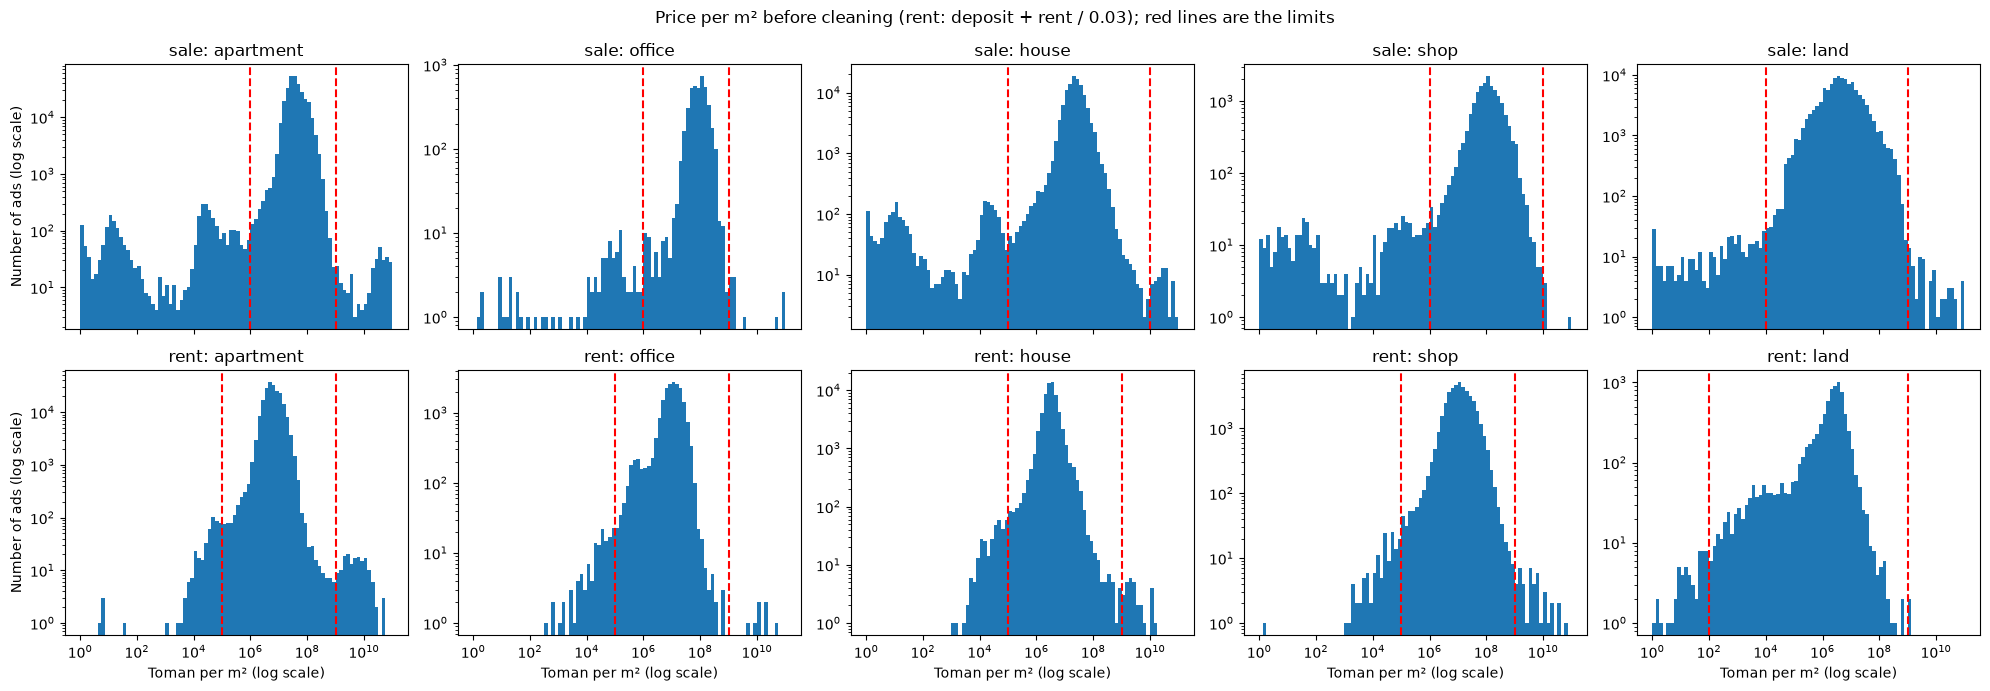

In [98]:
bins = np.logspace(0, 11, 89)
fig, axes = plt.subplots(2, 5, figsize=(20, 7), sharex=True)
for row, (deal, deal_mask) in enumerate([('sale', sale), ('rent', rent)]):
    for col, group in enumerate(limits.index):
        ax = axes[row, col]
        ax.hist(per_m2[deal_mask & (price_group == group)].dropna(), bins=bins)
        ax.axvline(limits.loc[group, f'{deal}_min'], color='red', linestyle='--')
        ax.axvline(limits.loc[group, f'{deal}_max'], color='red', linestyle='--')
        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_title(f'{deal}: {group}')
    axes[row, 0].set_ylabel('Number of ads (log scale)')
for ax in axes[1]:
    ax.set_xlabel('Toman per m² (log scale)')
fig.suptitle('Price per m² before cleaning (rent: deposit + rent / 0.03); red lines are the limits')
plt.tight_layout()
plt.show()

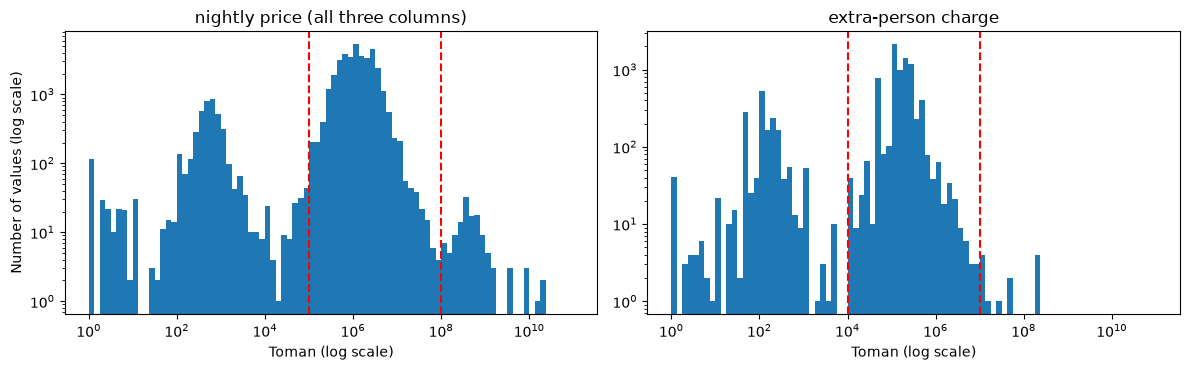

In [99]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (name, values, low, high) in zip(axes, [('nightly price (all three columns)', df[nightly_cols].stack(), 1e5, 1e8),
                                              ('extra-person charge', df['cost_per_extra_person'], 1e4, 1e7)]):
    ax.hist(values[values > 0], bins=bins)
    ax.axvline(low, color='red', linestyle='--')
    ax.axvline(high, color='red', linestyle='--')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_title(name)
    ax.set_xlabel('Toman (log scale)')
axes[0].set_ylabel('Number of values (log scale)')
plt.tight_layout()
plt.show()

In [100]:
# the limits of each ad's own group, aligned with df
row_limits = limits.reindex(price_group).set_axis(df.index)
min_per_m2 = row_limits['sale_min'].where(sale, row_limits['rent_min']).where(sale | rent)
max_per_m2 = row_limits['sale_max'].where(sale, row_limits['rent_max']).where(sale | rent)
no_size = df['building_size'].isna()
# out of range per m²; ads without a size are checked on their total price
implausible = ((per_m2 < min_per_m2) | (per_m2 >= max_per_m2)
               | (no_size & (sale | rent) & ((total_value < 1e6) | (total_value >= 1e13))))
df.loc[implausible & sale, ['cat3_slug', 'title', 'building_size', 'price_value']].sample(8, random_state=0)

,cat3_slug,title,building_size,price_value
91571,apartment-sell,115متر 2خواب عدل//فول,115.0,14900000.0
367122,house-villa-sell,ویلایی شهری,100.0,1111.0
36780,house-villa-sell,تک واحد دربست,47.0,950000.0
591825,industry-agriculture-business-sell,فروش شرکت تولیدی با کلیه تجهیزات وماشین آلات,NaN,1111.0
408428,apartment-sell,واحد 250 متری/صفر لوکس,250.0,21250000.0
106480,apartment-sell,فروش سه واحد آپارتمان,100.0,1111.0
259715,industry-agriculture-business-sell,باغ 4ساله امیر اباد شورین,1500.0,1000000.0
161687,house-villa-sell,زمین روستای کرکرق,1100.0,700.0


In [101]:
df.loc[implausible & rent, ['cat3_slug', 'title', 'building_size', 'credit_value', 'rent_value']].sample(6, random_state=0)

,cat3_slug,title,building_size,credit_value,rent_value
626703,house-villa-rent,خانه کاه گلی میباشد کبودرآهنگ روستای خان آباد ...,80.0,1000000.0,100000.0
938811,house-villa-rent,ویلا آپارتمانی,120.0,1000000.0,0.0
477006,apartment-rent,همخونه بدون حاشیه,87.0,1000000.0,100000.0
26134,house-villa-rent,ویلا باغ,1800.0,5000000.0,500000.0
165172,office-rent,500متر فلت اداری 6پارکینگ آیت الله کاشانی,500.0,1000000.0,1000000.0
372433,house-villa-rent,اجاره شهرک خواجو و ایرانمنش و گلدشت و ....,130.0,0.0,100000.0


In [102]:
df.loc[implausible & df['price_issue'].isna(), 'price_issue'] = 'implausible'
df.loc[implausible & sale, 'price_value'] = np.nan
df.loc[implausible & rent, ['credit_value', 'rent_value']] = np.nan
for col, low, high in [('rent_price_on_regular_days', 1e5, 1e8), ('rent_price_on_special_days', 1e5, 1e8),
                       ('rent_price_at_weekends', 1e5, 1e8), ('cost_per_extra_person', 1e4, 1e7)]:
    outside = (df[col] > 0) & ((df[col] < low) | (df[col] >= high))
    df.loc[outside & df['price_issue'].isna(), 'price_issue'] = 'implausible'
    df.loc[outside, col] = np.nan

In [ ]:
pd.crosstab(df['price_issue'].fillna('none'), df['deal_type'])

deal_type,daily_rent,rent,sale,service
price_issue,,,,
implausible,3050,1373,8526,0
none,25879,340569,570833,19230
placeholder,449,10737,14514,34
zero,318,0,1896,1


In [103]:
cleaned_total = df['price_value'].where(sale, df['credit_value'] + df['rent_value'] / 0.03)
(cleaned_total / df['building_size'] / 1e6).groupby([price_group, df['deal_type']]).median().unstack().round(1)

deal_type,rent,sale
price_group,,
apartment,5.9,36.6
house,3.2,23.0
land,2.3,4.5
office,10.4,90.0
shop,11.5,107.1


In [104]:
df[nightly_cols + ['cost_per_extra_person']].describe().loc[['count', 'min', '50%', 'max']]

,rent_price_on_regular_days,rent_price_on_special_days,rent_price_at_weekends,cost_per_extra_person
count,15246.0,8900.0,11658.0,8233.0
min,100000.0,100000.0,100000.0,0.0
50%,1000000.0,1500000.0,1400000.0,150000.0
max,90000000.0,65000000.0,96885577.0,8000000.0


## Step 19: Derived Price and Location Columns

<div dir="rtl">

- ستون `unified_price` تعریف پروژه را دنبال می‌کند: برای فروش همان قیمت فروش، و برای اجاره `credit_value + rent_value / 0.03` (هر ۱ میلیون رهن معادل ۳۰ هزار اجاره). برای اجاره‌ی شبانه (قیمت هر شب) و خدمات missing است.
- نرخ ۰.۰۳ با داده بررسی شد: ۷۱,۹۷۵ آگهی اجاره یک ترکیب دیگر رهن و اجاره را هم پیشنهاد داده‌اند، و median نرخی که از هر جفت به دست می‌آید دقیقاً ۰.۰۳ است (نیمه‌ی میانی از ۰.۰۲۹ تا ۰.۰۳).
- ستون `price_per_m2` برابر `unified_price / building_size` است، تا همه‌ی نوت‌بوک‌ها یک تعریف را استفاده کنند. برای `plot-old` این مقدار قیمت هر متر زمین است.
- ستون‌های `utm_x` و `utm_y` (به متر): همه‌ی نقطه‌ها از `UTM zone 39` استفاده می‌کنند (نصف‌النهار مرکزی ۵۱ درجه‌ی شرقی، که تهران در آن است)، چون ایران روی zoneهای ۳۸ تا ۴۱ پخش است و ترکیب zoneها فاصله‌ها را خراب می‌کند. اعوجاج کم است: فاصله‌ی تهران تا مشهد روی کره‌ی زمین ۷۴۳.۸ کیلومتر و در این مختصات ۷۴۵.۴ کیلومتر است.
- ستون‌های `transformed_credit` و `transformed_rent` بعد از این بررسی حذف می‌شوند، چون همان قیمت را با ترکیب دیگری تکرار می‌کنند. ستون‌های `transformable_price` و `rent_credit_transform` به‌عنوان flag نگه داشته می‌شوند و نشان می‌دهند ترکیب دیگری پیشنهاد شده.
- فقط بررسی، بدون تغییر: قیمت هر متر تقسیم بر median همان شهر و دسته. آگهی‌های `is_partial_offer` خیلی پایین‌تر از بقیه‌اند (median آن‌ها ۰.۰۹ برای اجاره و ۰.۲۸ برای فروش است)، که تأیید می‌کند قیمتشان قیمت کل ملک نیست. فروش مغازه‌هایی که به سرقفلی اشاره می‌کنند روی ۱.۳۳ است و بقیه‌ی مغازه‌ها روی ۰.۹۸.

</div>

In [105]:
pair = rent & df[['credit_value', 'rent_value', 'transformed_credit', 'transformed_rent']].notna().all(axis=1)
pair &= df['transformed_credit'] != df['credit_value']
# monthly rent given up per unit of extra deposit, between the two offers
implied_rate = (df['rent_value'] - df['transformed_rent']) / (df['transformed_credit'] - df['credit_value'])
pair.sum(), implied_rate[pair].quantile([0.05, 0.25, 0.5, 0.75, 0.95])

(np.int64(71975),
 0.05    0.020000
 0.25    0.029259
 0.50    0.030000
 0.75    0.030000
 0.95    0.040000
 dtype: float64)

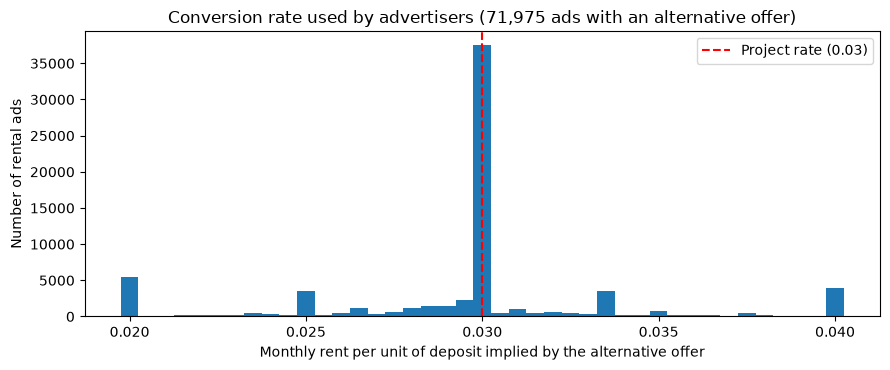

In [106]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(implied_rate[pair], bins=np.arange(0.01975, 0.04075, 0.0005))
ax.axvline(0.03, color='red', linestyle='--', label='Project rate (0.03)')
ax.set_xlabel('Monthly rent per unit of deposit implied by the alternative offer')
ax.set_ylabel('Number of rental ads')
ax.set_title(f'Conversion rate used by advertisers ({pair.sum():,} ads with an alternative offer)')
ax.legend()
plt.tight_layout()
plt.show()

In [107]:
df['unified_price'] = df['price_value'].where(sale, df['credit_value'] + df['rent_value'] / 0.03)
df.loc[~(sale | rent), 'unified_price'] = np.nan
df['price_per_m2'] = df['unified_price'] / df['building_size']
df.groupby('deal_type')[['unified_price', 'price_per_m2']].count()

,unified_price,price_per_m2
deal_type,,
daily_rent,0,0
rent,338647,336740
sale,540473,538342
service,0,0


In [108]:
(df.groupby('deal_type')[['unified_price', 'price_per_m2']].median() / 1e6).round(1)

,unified_price,price_per_m2
deal_type,,
daily_rent,NaN,NaN
rent,500.0,5.6
sale,2980.0,28.7
service,NaN,NaN


In [109]:
peer_median = df.groupby(['city_slug', 'cat3_slug'])['price_per_m2'].transform('median')
ratio = df['price_per_m2'] / peer_median
ratio.groupby([df['deal_type'], df['is_partial_offer']]).median().round(2)

deal_type   is_partial_offer
daily_rent  False                NaN
rent        False               1.00
            True                0.09
sale        False               1.00
            True                0.28
service     False                NaN
Name: price_per_m2, dtype: float64

In [110]:
ratio[shop_sale].groupby(df['mentions_key_money']).median().round(2)

mentions_key_money
False    0.98
True     1.33
Name: price_per_m2, dtype: float64

In [111]:
# EPSG:32639 = UTM zone 39N; always_xy means (lon, lat) order
to_utm = Transformer.from_crs('EPSG:4326', 'EPSG:32639', always_xy=True)
df['utm_x'], df['utm_y'] = to_utm.transform(df['location_longitude'].values, df['location_latitude'].values)

In [112]:
df[['location_latitude', 'utm_x', 'utm_y']].isna().sum(), df.loc[df['city_slug'] == 'tehran', ['utm_x', 'utm_y']].median()

(location_latitude    360096
 utm_x                360096
 utm_y                360096
 dtype: int64,
 utm_x    5.358646e+05
 utm_y    3.953912e+06
 dtype: float64)

In [113]:
df = df.drop(columns=['transformed_credit', 'transformed_rent'])
df.shape

(997409, 88)

## Step 20: Final Checks

<div dir="rtl">

همه‌ی قاعده‌ها روی جدول نهایی دوباره بررسی می‌شوند، تا مطمئن شویم هیچ مرحله‌ای کار یک مرحله‌ی قبلی را بی‌صدا خنثی نکرده است. اگر همه‌ی بررسی‌ها درست باشند، این سل چیزی چاپ نمی‌کند.

</div>

In [114]:
assert df.index.is_unique
for col in price_cols + ['building_size', 'land_size']:
    assert not is_placeholder(df[col]).any(), col
assert (df['building_size'].isna() | ((df['building_size'] >= min_size) & (df['building_size'] < max_size))).all()
assert (df['land_size'].isna() | df['land_size'].between(10, 100000, inclusive='left')).all()
assert (df['price_per_m2'].isna() | ((df['price_per_m2'] >= min_per_m2) & (df['price_per_m2'] < max_per_m2))).all()
assert (df[nightly_cols].isna() | ((df[nightly_cols] >= 1e5) & (df[nightly_cols] < 1e8))).all().all()
assert (df[lat].isna() | (df[lat].between(25, 40) & df[lon].between(44, 63.5))).all()
assert df.groupby([lat, lon]).size().max() < 5
assert df.loc[~(sale | rent), 'unified_price'].isna().all()
assert not (mezzanine & df['has_balcony'].isna() & df['has_balcony_combined'].fillna(False)).any()
assert df.loc[df['is_partial_offer'], 'deal_type'].isin(['sale', 'rent']).all()

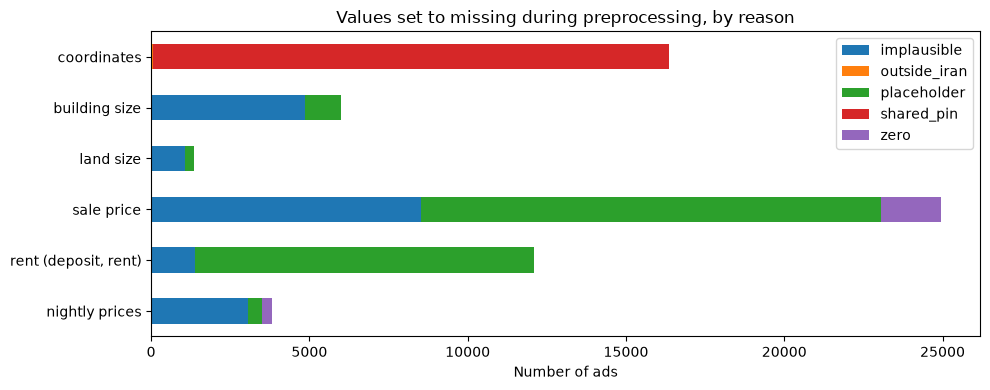

,implausible,outside_iran,placeholder,shared_pin,zero
coordinates,0,47,0,16321,0
building size,4866,0,1141,0,0
land size,1060,0,303,0,0
sale price,8526,0,14514,0,1896
"rent (deposit, rent)",1373,0,10737,0,0
nightly prices,3050,0,449,0,318


In [115]:
cleared = pd.DataFrame({
    'coordinates': df['location_issue'].value_counts(),
    'building size': df['building_size_issue'].value_counts(),
    'land size': df['land_size_issue'].value_counts(),
    'sale price': df.loc[sale, 'price_issue'].value_counts(),
    'rent (deposit, rent)': df.loc[rent, 'price_issue'].value_counts(),
    'nightly prices': df.loc[df['deal_type'] == 'daily_rent', 'price_issue'].value_counts()}).T.fillna(0).astype(int)
ax = cleared.plot(kind='barh', stacked=True, figsize=(10, 4))
ax.invert_yaxis()
ax.set_xlabel('Number of ads')
ax.set_title('Values set to missing during preprocessing, by reason')
plt.tight_layout()
plt.show()
cleared

## Column Guide

<div dir="rtl">

جدول تمیز ۹۹۷,۴۰۹ آگهی و ۸۸ ستون دارد (داده‌ی خام یک میلیون ردیف و ۶۰ ستون داشت). ستون‌های اصلی اسمشان را نگه داشته‌اند؛ مقدارهای خرابشان missing است و دلیلش در ستون‌هایی آمده که اسمشان به issue ختم می‌شود.

</div>

### Changed meaning in original columns

<div dir="rtl">

- در `construction_year` عدد ۱۳۷۰ یعنی ۱۳۷۰ یا قبل از آن.
- در `floor` و `total_floors_count` و `extra_person_capacity` عدد ۳۰ یعنی ۳۰ یا بیشتر؛ در `unit_per_floor` عدد ۹ یعنی ۹ یا بیشتر؛ و در `rooms_count` عدد ۵ یعنی ۵ یا بیشتر.
- ستون `building_size` در دسته‌ی `plot-old` مساحت زمین است.

</div>

### Labels

<div dir="rtl">

- ستون `deal_type` یکی از `sale, rent, daily_rent, service` است. قیمت‌ها فقط درون یک نوع معامله قابل مقایسه‌اند.
- ستون `is_residential_unit`: آپارتمان‌ها و خانه‌ها و ویلاها (فروش یا اجاره)، یعنی خانه‌هایی که فرضیه‌های متراژ درباره‌ی آن‌هاست.
- ستون `is_metro`: یکی از ۹ کلان‌شهر؛ وقتی شهر معلوم نیست، missing است.
- ستون `in_main_window`: مه تا دسامبر ۲۰۲۴، برای روندهای ماهانه. ستون `jalali_month`: برچسب تقریبی ماه شمسی، مثلاً <span dir="ltr">`1403-02 Ordibehesht`</span>.
- ستون `is_wanted_ad`: آگهی‌های درخواست و هم‌خانه؛ قیمتشان قیمت ملک نیست.
- ستون `is_partial_offer`: اجاره‌ی یک جای کار (صندلی، میز، لاین) یا فروش امتیاز عضویت در یک طرح مسکن؛ قیمت برای بخشی از ملک است.

</div>

### From the text

<div dir="rtl">

- ستون‌های `has_X_combined` برای `balcony, pool, sauna, jacuzzi, barbecue, security_guard`: مقدار فرم یا اشاره‌ی متن؛ missing یعنی نامعلوم. برای مغازه و ملک صنعتی یا کشاورزی از متنِ بالکن استفاده نشده (نیم‌طبقه).
- ستون‌های `mentions_X`: ستون‌های keyword که به‌عنوان feature به مدل می‌روند (نوساز، لوکس، مشاعات، لابی، پنت‌هاوس، کلنگی، وام، اقساطی، پیش‌فروش، مسکن مهر، سرقفلی و مشاور املاک).

</div>

### Quality flags

<div dir="rtl">

- ستون‌های `location_issue` و `building_size_issue` و `land_size_issue` و `price_issue`: دلیل missing شدن یک مقدار.
- ستون `far_from_city`: مختصاتی که بیش از ۵۰ کیلومتر از مرکز شهر فاصله دارد (مختصات نگه داشته شده).

</div>

### Derived

<div dir="rtl">

- ستون `unified_price`: قیمت فروش، یا برای اجاره `credit_value + rent_value / 0.03`. ستون `price_per_m2`: همین مقدار برای هر متر مربعِ `building_size`.
- ستون‌های `utm_x` و `utm_y`: در `UTM zone 39` و به متر.

</div>

### Typical filters

<div dir="rtl">

- تحلیل‌های قیمت و مدل: هر بار فقط یک `deal_type`، و فقط آگهی‌هایی که `is_wanted_ad` و `is_partial_offer` برایشان False است.
- روندهای ماهانه (سؤال ۳ و ۶): ستون `in_main_window`.
- فرضیه‌های متراژ: ستون `is_residential_unit`؛ برای آزمون کلان‌شهر، به‌صورت اختیاری آگهی‌هایی که `far_from_city` برایشان True است کنار گذاشته شوند.
- امکانات (سؤال ۹ و فرضیه‌ی امکانات لوکس): ستون‌های `has_X_combined`.
- فرضیه‌ی سند تجاری: ستون `mentions_key_money` به‌عنوان متغیر کنترل.

</div>

In [116]:
output_path = 'divar_clean.parquet'
df.to_parquet(output_path)

In [117]:
check = pd.read_parquet(output_path)
check.shape == df.shape, (check.dtypes == df.dtypes).all(), check.isna().equals(df.isna())

(True, np.False_, True)

In [118]:
del check